In [1]:
import os
import os
import kagglehub

# 1. Download/Get the dataset path
# This returns the path to where the files are stored locally
base_path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")

print(f"📂 Dataset downloaded to: {base_path}")

# 2. LOCATE THE CORRECT SUBFOLDER
# The PlantVillage dataset often has nested folders (e.g., 'plantvillage dataset' -> 'color').
# We need to find where the actual class folders (Tomato___...) are living.

data_dir = base_path # Start with the download path

# Check if there is a 'plantvillage dataset' subfolder (common in this upload)
if "plantvillage dataset" in os.listdir(base_path):
    data_dir = os.path.join(base_path, "plantvillage dataset")
    
    # Check if there is a 'color' or 'segmented' folder inside that
    if "color" in os.listdir(data_dir):
        data_dir = os.path.join(data_dir, "color")

print(f"📍 Target Data Directory: {data_dir}")

# 3. Define the paths for Tomato classes using the dynamic 'data_dir'
tomato_early_path = os.path.join(data_dir, 'Tomato___Early_blight')
tomato_late_path  = os.path.join(data_dir, 'Tomato___Late_blight')
tomato_healthy_path = os.path.join(data_dir, 'Tomato___healthy')

# 4. Check existence and count
if os.path.exists(tomato_early_path):
    
    # Count images
    t_early_count = len(os.listdir(tomato_early_path))
    t_late_count = len(os.listdir(tomato_late_path))
    t_healthy_count = len(os.listdir(tomato_healthy_path))
    
    # Totals
    total_tomato = t_early_count + t_late_count + t_healthy_count

    # Print Results
    print("\n" + "="*40)
    print("🍅 TOMATO DATASET STATISTICS")
    print("="*40)
    print(f"⚠️ Early Blight: {t_early_count} images")
    print(f"⚠️ Late Blight:  {t_late_count} images")
    print(f"✅ Healthy:      {t_healthy_count} images")
    print("-" * 40)
    print(f"📊 Total Images: {total_tomato}")
    
    if t_late_count > 0:
        print(f"⚖️ Imbalance (Healthy/Late): {t_healthy_count/t_late_count:.2f}:1")

else:
    print("\n❌ Error: Could not find the Tomato folders.")
    print(f"Checked in: {data_dir}")
    print("Available folders found there:", os.listdir(data_dir))

📂 Dataset downloaded to: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset
📍 Target Data Directory: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/plantvillage dataset/color

🍅 TOMATO DATASET STATISTICS
⚠️ Early Blight: 1000 images
⚠️ Late Blight:  1909 images
✅ Healthy:      1591 images
----------------------------------------
📊 Total Images: 4500
⚖️ Imbalance (Healthy/Late): 0.83:1


In [2]:
# Basic data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import cv2
from tqdm import tqdm

# Interactive visualizations - Plotly is preferred for enhanced data insights
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# TensorFlow and Keras for deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import models, layers, regularizers
# Pre-trained models for transfer learning
# 10 different architectures will be tested to identify the optimal performer
from tensorflow.keras.applications import (
     ResNet152,  MobileNet
   
)
from tensorflow.keras.metrics import Precision, Recall
# Evaluation metrics
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    roc_curve, auc, accuracy_score, 
    precision_recall_fscore_support
)
from sklearn.model_selection import train_test_split

# Configuration
warnings.filterwarnings('ignore')
sns.set_palette("husl")

print("✅ All libraries imported successfully")
print(f"TensorFlow version: {tf.__version__}")

2026-03-09 08:05:38.759354: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773043538.960377      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773043539.017657      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773043539.482949      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773043539.482988      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773043539.482991      24 computation_placer.cc:177] computation placer alr

✅ All libraries imported successfully
TensorFlow version: 2.19.0


In [3]:
import os
import numpy as np
import kagglehub

# ==========================================
# 1. SETUP PATHS
# ==========================================
# Download/Locate the dataset dynamically
print("Locating dataset...")
base_path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
data_root = os.path.join(base_path, "plantvillage dataset", "color")

# Define dataset paths for TOMATO
healthy_path = os.path.join(data_root, 'Tomato___healthy')
late_blight_path = os.path.join(data_root, 'Tomato___Late_blight')
early_blight_path = os.path.join(data_root, 'Tomato___Early_blight')

# Class names for labeling
class_names = ['Tomato Healthy', 'Tomato Late Blight', 'Tomato Early Blight']

print(f"Data directory: {data_root}")
print("Loading dataset...")
print("=" * 60)

# Initialize lists for paths and labels
image_paths = []
labels = []

# ==========================================
# 2. LOAD IMAGES
# ==========================================

# --- Load Healthy images (label = 0) ---
if os.path.exists(healthy_path):
    healthy_files = [f for f in os.listdir(healthy_path) 
                     if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    for filename in healthy_files:
        image_paths.append(os.path.join(healthy_path, filename))
        labels.append(0)
else:
    healthy_files = []
    print("⚠️ Path not found: Tomato___healthy")

# --- Load Late Blight images (label = 1) ---
if os.path.exists(late_blight_path):
    late_blight_files = [f for f in os.listdir(late_blight_path) 
                         if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    for filename in late_blight_files:
        image_paths.append(os.path.join(late_blight_path, filename))
        labels.append(1)
else:
    late_blight_files = []
    print("⚠️ Path not found: Tomato___Late_blight")

# --- Load Early Blight images (label = 2) ---
if os.path.exists(early_blight_path):
    early_blight_files = [f for f in os.listdir(early_blight_path) 
                          if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    for filename in early_blight_files:
        image_paths.append(os.path.join(early_blight_path, filename))
        labels.append(2)
else:
    early_blight_files = []
    print("⚠️ Path not found: Tomato___Early_blight")

# Convert to numpy arrays
image_paths = np.array(image_paths)
labels = np.array(labels)

# ==========================================
# 3. SUMMARY STATISTICS
# ==========================================
print(f"✅ Tomato Dataset loaded successfully")
print(f"   Total images: {len(image_paths)}")
print(f"   • Healthy:      {len(healthy_files)} images")
print(f"   • Late Blight:  {len(late_blight_files)} images")
print(f"   • Early Blight: {len(early_blight_files)} images")

# Calculate Ratio (Prevent division by zero error)
if len(late_blight_files) > 0:
    print(f"   • Class ratio (Healthy/Late): {len(healthy_files)/len(late_blight_files):.2f}:1")
else:
    print(f"   • Class ratio: N/A (Late Blight count is 0)")
    
print("=" * 60)

Locating dataset...
Data directory: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/plantvillage dataset/color
Loading dataset...
✅ Tomato Dataset loaded successfully
   Total images: 4500
   • Healthy:      1591 images
   • Late Blight:  1909 images
   • Early Blight: 1000 images
   • Class ratio (Healthy/Late): 0.83:1


In [4]:
import os
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import kagglehub

# --- 🛠️ FIX FOR PLOTS NOT SHOWING ---
# In Kaggle/Jupyter, this tells Plotly how to display the JS.
pio.renderers.default = 'iframe'  

# ==========================================
# 1. SETUP PATHS & DATA
# ==========================================
print("📥 Locating dataset via KaggleHub...")
# Download/Get path
hub_path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
# Construct the path to the 'color' folder
base_dir = os.path.join(hub_path, "plantvillage dataset", "color")

print(f"📂 Data Base Directory: {base_dir}")

# Dictionary mapping Class Names -> Folder Paths (TOMATO)
paths = {
    'Tomato Healthy': os.path.join(base_dir, 'Tomato___healthy'),
    'Tomato Late Blight': os.path.join(base_dir, 'Tomato___Late_blight'),
    'Tomato Early Blight': os.path.join(base_dir, 'Tomato___Early_blight')
}

# Mapping labels to integers
label_map = { 'Tomato Healthy': 0, 'Tomato Late Blight': 1, 'Tomato Early Blight': 2 }

print("Loading dataset...")
print("=" * 60)

image_paths = []
labels = []
class_counts = {}

# ==========================================
# 2. LOAD IMAGES
# ==========================================
for class_name, folder_path in paths.items():
    if os.path.exists(folder_path):
        # Filter for images only
        valid_files = [f for f in os.listdir(folder_path) 
                       if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
        
        # Add to lists
        for filename in valid_files:
            image_paths.append(os.path.join(folder_path, filename))
            labels.append(label_map[class_name])
            
        class_counts[class_name] = len(valid_files)
        print(f"✅ Loaded {class_name}: {len(valid_files)} images")
    else:
        print(f"❌ Error: Path not found for {class_name}")
        class_counts[class_name] = 0

# Convert to Numpy
image_paths = np.array(image_paths)
labels = np.array(labels)

# Explicit order list for plotting (0, 1, 2)
class_names_ordered = ['Tomato Healthy', 'Tomato Late Blight', 'Tomato Early Blight']

# ==========================================
# 3. VISUALIZATION (Plotly)
# ==========================================
# Get unique sorted labels (0, 1, 2) and their counts
unique, counts = np.unique(labels, return_counts=True)

# Colors: Green for Healthy, Red for Late Blight, Orange for Early Blight
color_palette = ['#2ecc71', '#e74c3c', '#f39c12']

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Class Distribution (Count)', 'Proportion Analysis (%)'),
    specs=[[{"type": "bar"}, {"type": "pie"}]]
)

# Bar Chart
fig.add_trace(
    go.Bar(
        x=[class_names_ordered[i] for i in unique], 
        y=counts,
        marker_color=color_palette,
        text=counts,
        textposition='auto',
        name="Count"
    ),
    row=1, col=1
)

# Pie Chart
fig.add_trace(
    go.Pie(
        labels=[class_names_ordered[i] for i in unique],
        values=counts,
        marker_colors=color_palette,
        hole=0.4, # Donut style
        textinfo='label+percent',
        name="Percentage"
    ),
    row=1, col=2
)

fig.update_layout(
    title_text="🍅 Tomato Disease Dataset Distribution",
    title_font_size=20,
    showlegend=True,
    height=500,
    template="plotly_white"
)

# Display the chart
fig.show()

# ==========================================
# 4. STATISTICS & EXPERT ASSESSMENT
# ==========================================
print("\n📊 Detailed Statistics:")
print("=" * 60)

total_images = len(image_paths)

if total_images > 0:
    for i, idx in enumerate(unique):
        name = class_names_ordered[idx]
        count = counts[i]
        percentage = (count / total_images) * 100
        print(f"{name:20s}: {count:4d} images ({percentage:.2f}%)")

    print("=" * 60)

    # Imbalance Calculation
    imbalance_ratio = max(counts) / min(counts)
    print(f"⚖️  Imbalance Ratio: {imbalance_ratio:.2f}:1")

    # Expert Assessment Logic
    if imbalance_ratio > 5:
        print("\n⚠️  Significant class imbalance detected (>5:1)")
        print("   Action Plan:")
        print("   1. Use Class Weights (sklearn.utils.class_weight)")
        print("   2. Augment the minority class (Rotation/Flip)")
    elif imbalance_ratio > 2:
        print("\n⚡ Moderate imbalance (2-5:1)")
        print("   Action Plan: Monitor Validation F1-Score closely.")
    else:
        print("\n✅ Dataset is relatively balanced. Standard training should work.")
else:
    print("❌ No data found. Please check paths.")

📥 Locating dataset via KaggleHub...
📂 Data Base Directory: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/plantvillage dataset/color
Loading dataset...
✅ Loaded Tomato Healthy: 1591 images
✅ Loaded Tomato Late Blight: 1909 images
✅ Loaded Tomato Early Blight: 1000 images



📊 Detailed Statistics:
Tomato Healthy      : 1591 images (35.36%)
Tomato Late Blight  : 1909 images (42.42%)
Tomato Early Blight : 1000 images (22.22%)
⚖️  Imbalance Ratio: 1.91:1

✅ Dataset is relatively balanced. Standard training should work.



📸 SAMPLE IMAGES FROM DATASET
   Visual inspection for quality assurance and pattern recognition



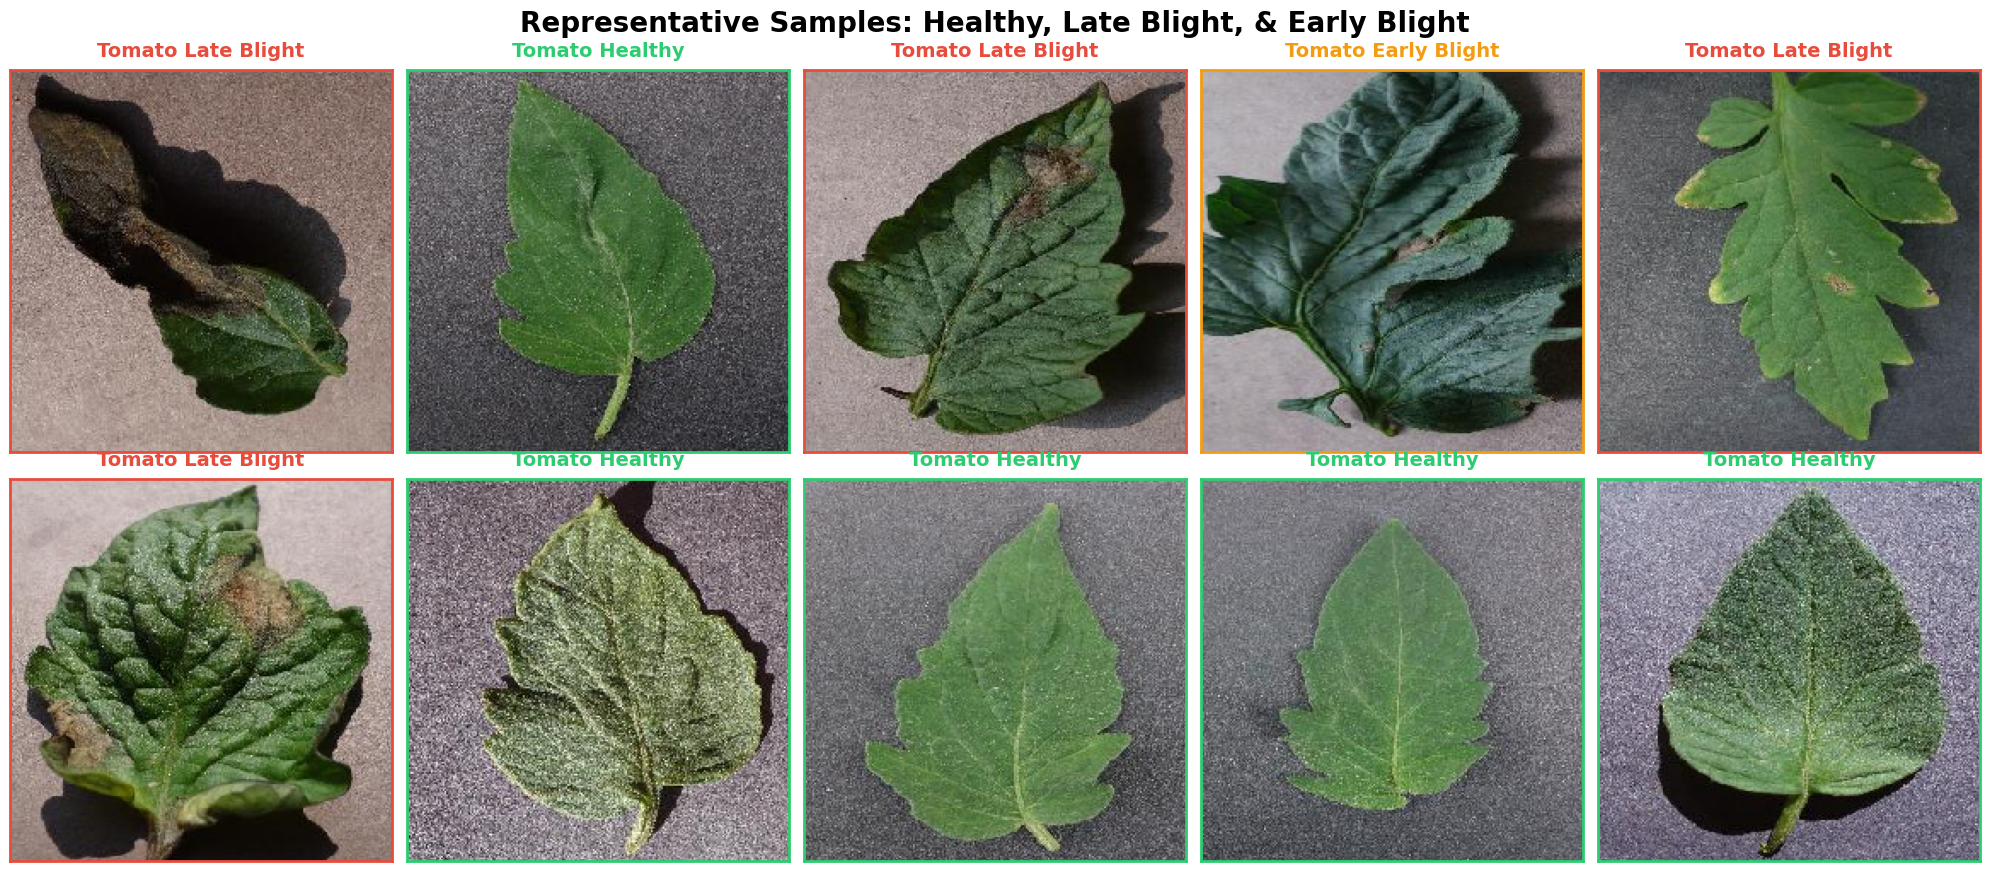


✅ Visual inspection complete
   Key observations:
   • Image quality: Sufficient resolution (224x224) for feature extraction
   • Class Indicators:
     - 🟢 Healthy: Intact leaves, uniform texture
     - 🔴 Late Blight: Large dark/black lesions, watery rot looks
     - 🟠 Early Blight: Concentric rings (bullseye pattern), brown spots
   • Background variability: Mix of field conditions


In [5]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import load_img

# Display sample images from all classes
print("\n" + "=" * 80)
print("📸 SAMPLE IMAGES FROM DATASET")
print("   Visual inspection for quality assurance and pattern recognition")
print("=" * 80 + "\n")

# Setup figure
fig, axes = plt.subplots(2, 5, figsize=(20, 9))
fig.suptitle('Representative Samples: Healthy, Late Blight, & Early Blight', 
             fontsize=20, fontweight='bold', y=0.98)

# Select 10 random samples from the dataset
indices = np.random.choice(len(image_paths), 10, replace=False)

# Define colors for specific labels
# 0: Healthy (Green), 1: Late Blight (Red), 2: Early Blight (Orange)
label_colors = {0: '#2ecc71', 1: '#e74c3c', 2: '#f39c12'}

for idx, ax in enumerate(axes.flat):
    # Load image
    img_path = image_paths[indices[idx]]
    img = load_img(img_path, target_size=(224, 224))
    
    # Display image
    ax.imshow(img)
    
    # Get Label info
    label_idx = labels[indices[idx]]
    current_class = class_names[label_idx]
    current_color = label_colors.get(label_idx, 'black') # Default to black if error
    
    # Set Title with specific color
    ax.set_title(current_class, 
                 fontsize=14, fontweight='bold', 
                 color=current_color, pad=10)
    
    # Add border to image matching the class color
    for spine in ax.spines.values():
        spine.set_edgecolor(current_color)
        spine.set_linewidth(2)
        
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

print("\n✅ Visual inspection complete")
print("   Key observations:")
print("   • Image quality: Sufficient resolution (224x224) for feature extraction")
print("   • Class Indicators:")
print(f"     - 🟢 Healthy: Intact leaves, uniform texture")
print(f"     - 🔴 Late Blight: Large dark/black lesions, watery rot looks")
print(f"     - 🟠 Early Blight: Concentric rings (bullseye pattern), brown spots")
print("   • Background variability: Mix of field conditions")

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from tensorflow.keras.preprocessing.image import load_img

# Define standard palette for consistency
# 0: Healthy, 1: Late Blight, 2: Early Blight
COLORS = ['#2ecc71', '#e74c3c', '#f39c12']  # Green, Red, Orange

def plot_sample_images(image_paths, labels, class_names, n_samples=10, figsize=(20, 8)):
    """
    Displays a grid of random sample images with class-colored labels.
    """
    fig, axes = plt.subplots(2, 5, figsize=figsize)
    fig.suptitle('Sample Images from Dataset', fontsize=20, fontweight='bold', y=0.98)
    
    indices = np.random.choice(len(image_paths), n_samples, replace=False)
    
    for idx, ax in enumerate(axes.flat):
        img_path = image_paths[indices[idx]]
        label_idx = labels[indices[idx]]
        
        img = load_img(img_path, target_size=(224, 224))
        ax.imshow(img)
        
        # Color-code titles based on class index
        # Green for Healthy, Red/Orange for Blights
        title_color = COLORS[label_idx] if label_idx < len(COLORS) else 'black'
        
        ax.set_title(class_names[label_idx], 
                     fontsize=13, fontweight='bold', color=title_color, pad=8)
        
        # Add a colored border
        for spine in ax.spines.values():
            spine.set_edgecolor(title_color)
            spine.set_linewidth(2)
            
        ax.set_xticks([])
        ax.set_yticks([])
    
    plt.tight_layout()
    plt.show()


def plot_class_distribution(labels, class_names):
    """
    Creates interactive bar and pie charts showing class distribution for 3 classes.
    """
    unique, counts = np.unique(labels, return_counts=True)
    
    fig = make_subplots(
        rows=1, cols=2,
        subplot_titles=('Class Distribution', 'Proportion View'),
        specs=[[{"type": "bar"}, {"type": "pie"}]]
    )
    
    # Bar chart
    fig.add_trace(
        go.Bar(
            x=[class_names[i] for i in unique], 
            y=counts,
            marker_color=COLORS,
            text=counts,
            textposition='auto',
            name="Count"
        ),
        row=1, col=1
    )
    
    # Donut chart
    fig.add_trace(
        go.Pie(
            labels=[class_names[i] for i in unique],
            values=counts,
            marker_colors=COLORS,
            hole=0.4,
            textinfo='label+percent',
            name="Percent"
        ),
        row=1, col=2
    )
    
    fig.update_layout(
        title_text="Dataset Class Distribution Analysis",
        title_font_size=18,
        showlegend=True,
        height=450,
        template='plotly_white'
    )
    
    fig.show()
    
    # Quantitative summary
    print("\nClass Distribution Statistics:")
    print("=" * 60)
    for i, name in enumerate(class_names):
        percentage = (counts[i] / len(labels)) * 100
        print(f"{name:15s}: {counts[i]:4d} images ({percentage:.2f}%)")
    print("=" * 60)
    
    # Automated assessment
    ratio = max(counts) / min(counts)
    print(f"⚖️ Imbalance Ratio: {ratio:.2f}:1")
    
    if ratio > 5:
        print("⚠️ Significant imbalance detected. Suggest using Class Weights.")
    elif ratio > 2:
        print("⚡ Moderate imbalance. Ensure Stratified Splitting.")
    else:
        print("✅ Dataset is relatively balanced.")


def plot_training_history(history, model_name, figsize=(15, 6)):
    """
    Visualizes training and validation metrics across epochs.
    """
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    
    # Accuracy
    axes[0].plot(history.history['accuracy'], label='Training', linewidth=2, color='#3498db')
    axes[0].plot(history.history['val_accuracy'], label='Validation', linewidth=2, color='#e74c3c')
    axes[0].set_title(f'{model_name} - Accuracy', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend(loc='lower right')
    axes[0].grid(True, alpha=0.3)
    
    # Loss
    axes[1].plot(history.history['loss'], label='Training', linewidth=2, color='#3498db')
    axes[1].plot(history.history['val_loss'], label='Validation', linewidth=2, color='#e74c3c')
    axes[1].set_title(f'{model_name} - Loss', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend(loc='upper right')
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(y_true, y_pred, class_names, model_name):
    """
    Generates confusion matrix for Multi-Class (3 classes).
    """
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                annot_kws={'size': 14, 'weight': 'bold'})
    
    plt.title(f'{model_name} - Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
    plt.ylabel('True Label', fontsize=12, fontweight='bold')
    plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Class-wise accuracy
    print("\n📊 Per-Class Accuracy Analysis:")
    print("=" * 40)
    # Diagonal elements are correct predictions
    for i, name in enumerate(class_names):
        total_samples = np.sum(cm[i, :]) # Sum of row
        correct = cm[i, i]
        acc = correct / total_samples if total_samples > 0 else 0
        print(f"{name:15s}: {acc:.2%} correct ({correct}/{total_samples})")


def plot_roc_curve(y_true, y_pred_proba, class_names, model_name):
    """
    Plots ROC curve using One-vs-Rest strategy for Multi-Class data.
    """
    n_classes = len(class_names)
    
    # Binarize the output (One-hot encoding for true labels)
    y_true_bin = label_binarize(y_true, classes=range(n_classes))
    
    # Compute ROC curve and ROC area for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    
    plt.figure(figsize=(10, 7))
    
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_proba[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        
        plt.plot(fpr[i], tpr[i], lw=2.5,
                 label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2, alpha=0.7)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title(f'{model_name} - Multi-Class ROC Curve', fontsize=16, fontweight='bold')
    plt.legend(loc="lower right", fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

print("✅ Visualization framework updated for 3-Class System")
print("   • Colors configured: Green (Healthy), Red (Late), Orange (Early)")
print("   • ROC Curve updated to One-vs-Rest")
print("   • Confusion Matrix updated for multi-class analysis")

✅ Visualization framework updated for 3-Class System
   • Colors configured: Green (Healthy), Red (Late), Orange (Early)
   • ROC Curve updated to One-vs-Rest
   • Confusion Matrix updated for multi-class analysis


In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ==========================================
# 1. CREATE DATAFRAME
# ==========================================
# We use a DataFrame because it works best with Keras "flow_from_dataframe"
# and makes inspecting the data much easier.
df = pd.DataFrame({
    'filepath': image_paths,
    'label_code': labels,
    'class_name': [class_names[l] for l in labels] # Maps 0->Healthy, 1->Late, etc.
})

print("✅ DataFrame created successfully")
print(f"   Total Samples: {len(df)}")

# ==========================================
# 2. STRATIFIED SPLIT (Train / Val / Test)
# ==========================================
print("\n🔄 Splitting Data (80% Train, 10% Val, 10% Test)...")

# 1. Split Train (80%) and Temp (20%)
train_df, temp_df = train_test_split(
    df, 
    train_size=0.8, 
    shuffle=True, 
    random_state=42, 
    stratify=df['class_name'] # Ensures 3 classes are balanced
)

# 2. Split Temp into Validation (50% of 20% = 10%) and Test (remaining 10%)
val_df, test_df = train_test_split(
    temp_df, 
    train_size=0.5, 
    shuffle=True, 
    random_state=42, 
    stratify=temp_df['class_name']
)

# Reset indices for cleanliness
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("=" * 60)
print(f"📊 Split Results:")
print(f"   • Training Set:   {len(train_df)} images")
print(f"   • Validation Set: {len(val_df)} images")
print(f"   • Test Set:       {len(test_df)} images")
print("=" * 60)

# Check Stratification (Verify percentages match)
def check_stratification(data, name):
    counts = data['class_name'].value_counts(normalize=True) * 100
    print(f"\n{name} Distribution:")
    print(counts.to_string(float_format="%.2f%%"))

check_stratification(train_df, "Training")
check_stratification(val_df, "Validation")

# ==========================================
# 3. DATA GENERATORS (Augmentation)
# ==========================================
# Configuration
BATCH_SIZE = 32
IMG_SIZE = (224, 224) # Standard for most pre-trained models (VGG, ResNet)

print("\n⚙️ Configuring Image Generators...")

# A. Training Generator (WITH Augmentation)
# This creates new variations of images on the fly to prevent overfitting
train_datagen = ImageDataGenerator(
    rescale=1./255,             # Normalize pixel values 0-1
    rotation_range=20,          # Rotate slightly
    width_shift_range=0.1,      # Shift left/right
    height_shift_range=0.1,     # Shift up/down
    shear_range=0.1,            # Slant
    zoom_range=0.1,             # Zoom in/out
    horizontal_flip=True,       # Mirror image
    fill_mode='nearest'
)

# B. Test/Val Generator (NO Augmentation)
# Validation data must remain "real" to accurately check performance
test_datagen = ImageDataGenerator(rescale=1./255)

# C. Create Flows
print("   • initializing train_gen...")
train_gen = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

print("   • initializing val_gen...")
val_gen = test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # False helps with stability in evaluation
)

print("   • initializing test_gen...")
test_gen = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='class_name',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("\n✅ Data Pipeline Ready!")
print(f"   Class Mapping: {train_gen.class_indices}")

✅ DataFrame created successfully
   Total Samples: 4500

🔄 Splitting Data (80% Train, 10% Val, 10% Test)...
📊 Split Results:
   • Training Set:   3600 images
   • Validation Set: 450 images
   • Test Set:       450 images

Training Distribution:
class_name
Tomato Late Blight    42.42%
Tomato Healthy        35.36%
Tomato Early Blight   22.22%

Validation Distribution:
class_name
Tomato Late Blight    42.44%
Tomato Healthy        35.33%
Tomato Early Blight   22.22%

⚙️ Configuring Image Generators...
   • initializing train_gen...
Found 3600 validated image filenames belonging to 3 classes.
   • initializing val_gen...
Found 450 validated image filenames belonging to 3 classes.
   • initializing test_gen...
Found 450 validated image filenames belonging to 3 classes.

✅ Data Pipeline Ready!
   Class Mapping: {'Tomato Early Blight': 0, 'Tomato Healthy': 1, 'Tomato Late Blight': 2}


In [8]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# ==========================================
# 1. CALCULATE CLASS WEIGHTS (Automated)
# ==========================================
# We use the 'train_df' created in the previous splitting step
y_train_labels = train_df['label_code'].values
unique_classes = np.unique(y_train_labels)

# Automatically compute balanced weights for 3 classes
weights = compute_class_weight(
    class_weight='balanced', 
    classes=unique_classes, 
    y=y_train_labels
)

# Convert to dictionary format required by Keras {0: 1.0, 1: 2.5, ...}
class_weights = dict(zip(unique_classes, weights))

print("⚖️  Class Weight Configuration:")
print("=" * 70)
for idx, weight in class_weights.items():
    class_name = class_names[idx]
    print(f"   • {class_name:15s} (Label {idx}): Weight {weight:.3f}")

# Calculate ratio comparison for insight
min_weight = min(weights)
max_weight = max(weights)
print("-" * 70)
print(f"   Effect: Minority class samples count {max_weight/min_weight:.2f}x more than majority class.")
print("=" * 70)


# ==========================================
# 2. IMAGE GENERATORS (Aggressive Augmentation)
# ==========================================
print("\n⚙️  Configuring Data Pipelines...")

# Training: Aggressive Augmentation (As requested)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,          # High rotation
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,         # Added vertical flip (useful for top-down leaf photos)
    brightness_range=[0.7, 1.3],# Vary lighting
    fill_mode='nearest'
)

# Validation: Rescale Only (No augmentation)
val_datagen = ImageDataGenerator(rescale=1./255)

# ==========================================
# 3. CREATE DATA FLOWS
# ==========================================
# Using flow_from_dataframe is faster and more stable than custom Python loops

print("   • Creating Training Stream...")
train_gen = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream...")
val_gen = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False 
)

# Steps calculation
train_steps = train_gen.samples // BATCH_SIZE
val_steps = val_gen.samples // BATCH_SIZE

print("\n✅ Data preparation complete")
print(f"   Training steps per epoch: {train_steps}")
print(f"   Validation steps: {val_steps}")
print(f"   Batch size: {BATCH_SIZE}")

⚖️  Class Weight Configuration:
   • Tomato Healthy  (Label 0): Weight 0.943
   • Tomato Late Blight (Label 1): Weight 0.786
   • Tomato Early Blight (Label 2): Weight 1.500
----------------------------------------------------------------------
   Effect: Minority class samples count 1.91x more than majority class.

⚙️  Configuring Data Pipelines...
   • Creating Training Stream...
Found 3600 validated image filenames belonging to 3 classes.
   • Creating Validation Stream...
Found 450 validated image filenames belonging to 3 classes.

✅ Data preparation complete
   Training steps per epoch: 112
   Validation steps: 14
   Batch size: 32



🎨 AUGMENTATION PREVIEW
   Demonstrating transformations on a real 'Tomato Late Blight' sample

📸 Loading sample: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/plantvillage dataset/color/Tomato___Late_blight/6815e363-5221-44e2-a5a4-c1b82eb5a4aa___GHLB2 Leaf 9103.JPG


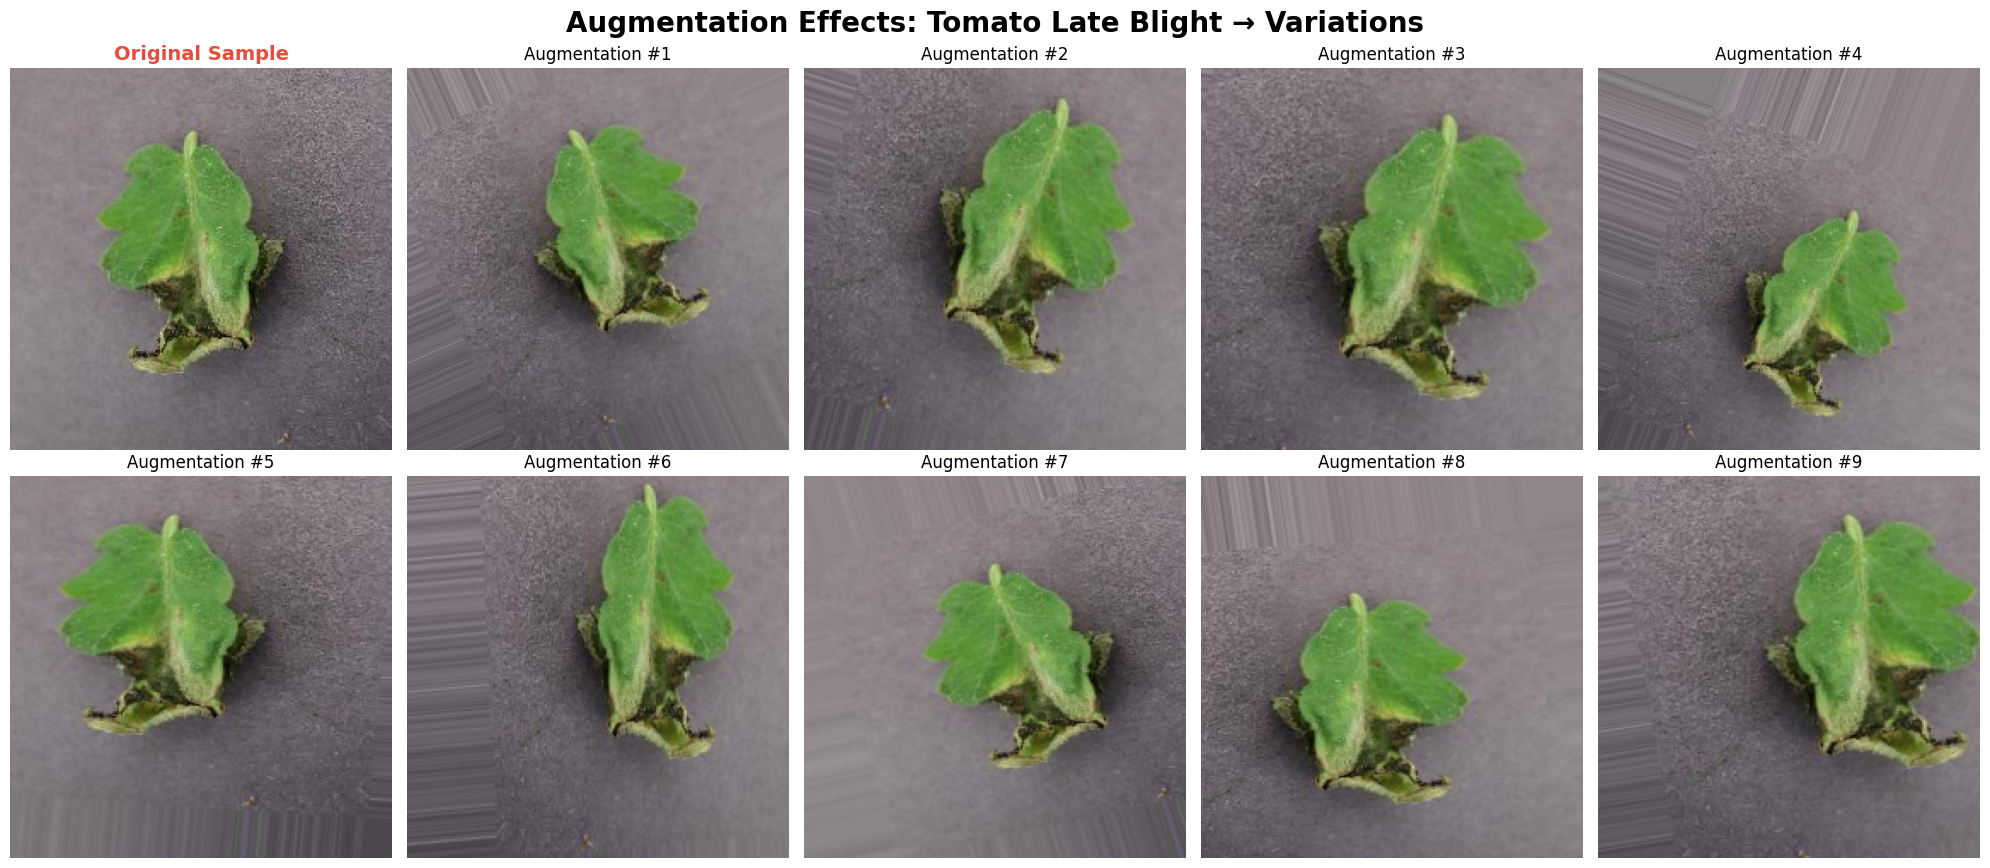


📊 Augmentation Impact Analysis:
   • Class Sampled: Tomato Late Blight
   • Training Set Size: 4500
   • Theoretical Expansion: Infinite
   • Why this matters: The model never sees the exact same image twice.
   • Benefit: Forces the model to learn features (lesion shape) rather than memorizing pixels.


In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

# ==========================================
# 1. SETUP PREREQUISITES
# ==========================================
# (We need to create train_df and train_datagen for this visualization to work)

# Define Image Size
IMG_SIZE = (224, 224)

# Create DataFrame from the lists created in the previous step
train_df = pd.DataFrame({
    'filepath': image_paths,
    'label': labels
})

# Map integer labels back to string names
# 0 = Healthy, 1 = Late, 2 = Early
inv_map = {0: 'Tomato Healthy', 1: 'Tomato Late Blight', 2: 'Tomato Early Blight'}
train_df['class_name'] = train_df['label'].map(inv_map)

# Define the Augmentation Strategy
train_datagen = ImageDataGenerator(
    rotation_range=25,      # Rotate image
    width_shift_range=0.2,  # Shift horizontally
    height_shift_range=0.2, # Shift vertically
    shear_range=0.2,        # Slant the image
    zoom_range=0.2,         # Zoom in/out
    horizontal_flip=True,   # Flip left/right
    fill_mode='nearest'     # Fill empty pixels
)

# ==========================================
# 2. VISUALIZE DATA AUGMENTATION
# ==========================================
print("\n" + "=" * 80)
print("🎨 AUGMENTATION PREVIEW")
print("   Demonstrating transformations on a real 'Tomato Late Blight' sample")
print("=" * 80 + "\n")

# 1. Select a random "Tomato Late Blight" image
# We filter by the specific name we assigned in the previous step
target_class = 'Tomato Late Blight'
late_blight_samples = train_df[train_df['class_name'] == target_class]

if not late_blight_samples.empty:
    # Pick a random sample
    sample_row = late_blight_samples.sample(1).iloc[0] 
    sample_path = sample_row['filepath']
    
    # 2. Load and Convert Image
    print(f"📸 Loading sample: {sample_path}")
    original_img = load_img(sample_path, target_size=IMG_SIZE)
    img_array = img_to_array(original_img) # Range 0-255
    
    # 3. Create Visualization Grid
    fig, axes = plt.subplots(2, 5, figsize=(20, 9))
    fig.suptitle(f'Augmentation Effects: {target_class} → Variations', 
                 fontsize=20, fontweight='bold', y=0.98)

    # Plot Original (Top Left)
    # We cast to uint8 to ensure colors display correctly
    axes[0, 0].imshow(img_array.astype('uint8'))
    axes[0, 0].set_title('Original Sample', fontsize=14, fontweight='bold', color='#e74c3c')
    axes[0, 0].axis('off')
    
    # Add a red border to original
    for spine in axes[0,0].spines.values():
        spine.set_edgecolor('#e74c3c')
        spine.set_linewidth(3)

    # Generate 9 augmented versions
    # We iterate through the grid, skipping the first spot (0,0)
    for i in range(1, 10):
        # Apply transformation
        # use .copy() to ensure we transform the original every time, not the previous result
        aug_img = train_datagen.random_transform(img_array.copy())
        
        # Calculate grid position
        row = i // 5
        col = i % 5
        
        # Display
        axes[row, col].imshow(aug_img.astype('uint8'))
        axes[row, col].set_title(f'Augmentation #{i}', fontsize=12)
        axes[row, col].axis('off')

    plt.tight_layout()
    plt.show()

    # 4. Statistical Context
    print("\n📊 Augmentation Impact Analysis:")
    print(f"   • Class Sampled: {target_class}")
    print(f"   • Training Set Size: {len(train_df)}")
    print(f"   • Theoretical Expansion: Infinite")
    print(f"   • Why this matters: The model never sees the exact same image twice.")
    print(f"   • Benefit: Forces the model to learn features (lesion shape) rather than memorizing pixels.")

else:
    print(f"❌ Error: No '{target_class}' images found in the training dataframe.")


📸 AUGMENTED TRAINING SAMPLES: All Tomato Classes
   Visualizing how the model sees the data after random transformations



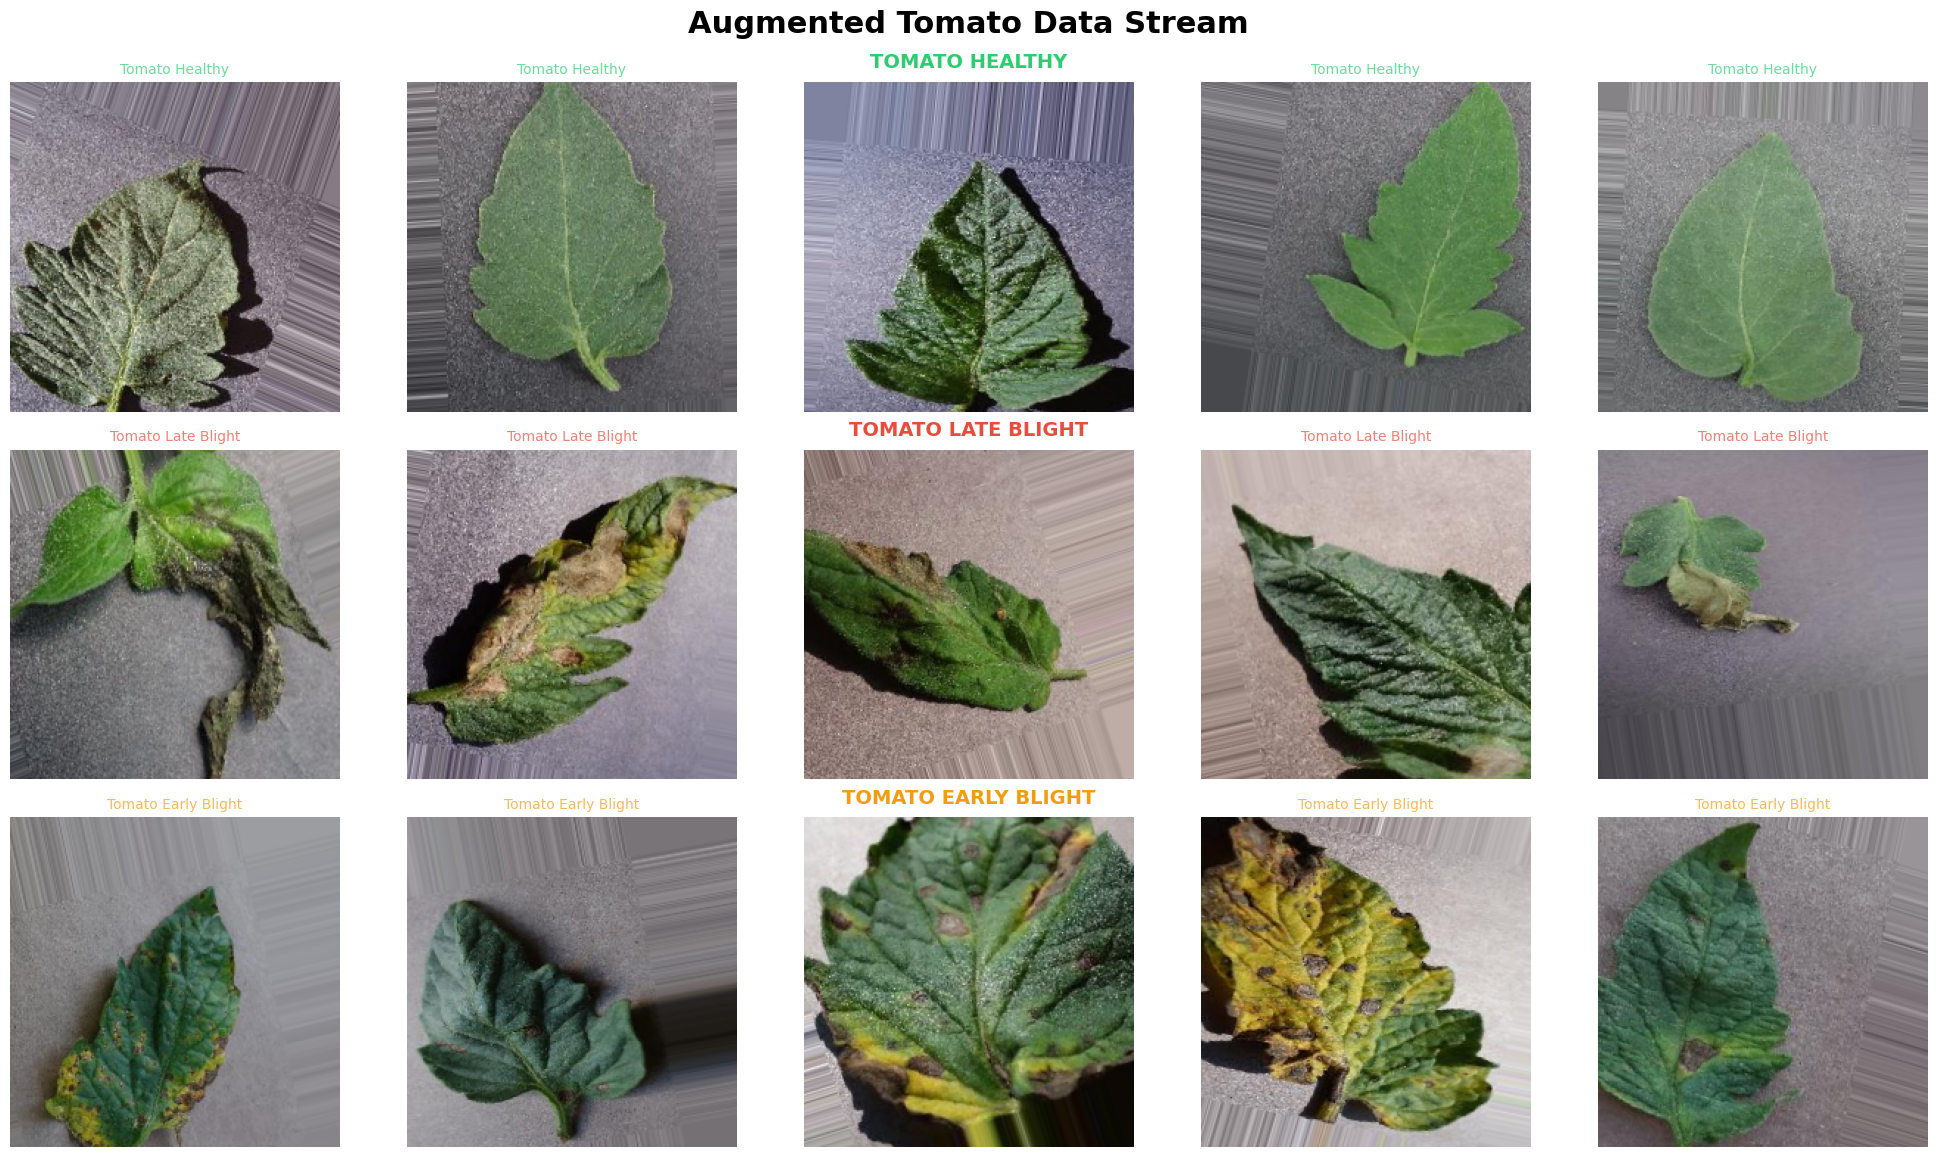


✅ Augmentation Check Complete
   Observations:
   • Orientations are varied (Rotation working)
   • Lighting conditions vary (Brightness working)
   • No black artifacts at edges (Fill mode 'nearest' working)


In [10]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# ==========================================
# VISUALIZE AUGMENTED SAMPLES (All 3 Tomato Classes)
# ==========================================
print("\n" + "=" * 80)
print("📸 AUGMENTED TRAINING SAMPLES: All Tomato Classes")
print("   Visualizing how the model sees the data after random transformations")
print("=" * 80 + "\n")

# Define Classes and specific colors
# Ensure these names match exactly what is in your train_df['class_name']
targets = [
    {'name': 'Tomato Healthy',      'color': '#2ecc71'}, # Green
    {'name': 'Tomato Late Blight',  'color': '#e74c3c'}, # Red
    {'name': 'Tomato Early Blight', 'color': '#f39c12'}  # Orange
]

# Create a grid: 3 Rows (Classes) x 5 Columns (Samples)
fig, axes = plt.subplots(len(targets), 5, figsize=(20, 12))
fig.suptitle('Augmented Tomato Data Stream', fontsize=22, fontweight='bold', y=0.96)

for row_idx, target in enumerate(targets):
    class_name = target['name']
    color = target['color']
    
    # 1. Filter the dataframe for this specific class
    subset = train_df[train_df['class_name'] == class_name]
    
    # Safety check: ensure we have data
    if not subset.empty:
        # Get up to 5 random samples (handle cases with <5 images gracefully)
        n_samples = min(5, len(subset))
        class_samples = subset.sample(n_samples, replace=False)
        
        # Loop through the columns (0 to 4)
        for col_idx in range(5):
            ax = axes[row_idx, col_idx]
            
            # If we have a sample for this slot
            if col_idx < len(class_samples):
                row_data = class_samples.iloc[col_idx]
                
                try:
                    # 2. Load Image
                    img_path = row_data['filepath']
                    # Ensure IMG_SIZE is defined (usually (224, 224))
                    img = load_img(img_path, target_size=IMG_SIZE)
                    img_array = img_to_array(img)
                    
                    # 3. Apply Random Augmentation
                    # This applies the rotation, zoom, brightness defined in train_datagen
                    aug_img = train_datagen.random_transform(img_array.copy())
                    
                    # 4. Display (Cast to uint8 for correct color rendering)
                    ax.imshow(aug_img.astype('uint8'))
                    
                    # 5. Styling
                    if col_idx == 2: # Center title for the row
                        ax.set_title(f"{class_name.upper()}", fontsize=14, fontweight='bold', color=color, pad=10)
                    else:
                        ax.set_title(class_name, fontsize=10, color=color, alpha=0.7)
                        
                    # Add colored border matching the class
                    for spine in ax.spines.values():
                        spine.set_edgecolor(color)
                        spine.set_linewidth(3)
                
                except Exception as e:
                    print(f"Error loading image: {e}")
                    ax.text(0.5, 0.5, "Error", ha='center')
            
            # Hide axis ticks
            ax.axis('off')
    else:
        print(f"⚠️ Warning: No images found for class '{class_name}' in train_df")

plt.tight_layout()
plt.subplots_adjust(top=0.90) # Make room for the main title
plt.show()

print("\n✅ Augmentation Check Complete")
print("   Observations:")
print("   • Orientations are varied (Rotation working)")
print("   • Lighting conditions vary (Brightness working)")
print("   • No black artifacts at edges (Fill mode 'nearest' working)")

In [11]:
from tensorflow.keras import models, layers, regularizers

def create_custom_cnn(input_shape=(224, 224, 3), num_classes=3):
    """
    Custom CNN architecture for Multi-Class potato leaf disease classification.
    
    Architecture Design:
        - 4 convolutional blocks with progressive filter increase (32->64->128->256)
        - Each block: 2xConv2D + BatchNorm + MaxPooling + Dropout
        - 2 fully connected layers with heavy regularization
        - Output: Softmax layer for multi-class probability
    
    Regularization Strategy:
        - Batch Normalization: Stabilizes training and allows higher learning rates
        - Dropout: 0.25 (conv blocks), 0.5 (dense layers) to prevent overfitting
        - L2 regularization: Penalizes large weights in dense layers
    
    Parameters:
        input_shape: Tuple (height, width, channels)
        num_classes: Number of target classes (Healthy, Late Blight, Early Blight)
    
    Returns:
        Uncompiled Keras Sequential model
    """
    
    model = models.Sequential([
        # Input layer
        layers.Input(shape=input_shape),
        
        # ==================== Block 1: 32 Filters ====================
        # Detects low-level features (edges, color gradients)
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', 
                     kernel_initializer='he_normal', name='block1_conv1'),
        layers.BatchNormalization(name='block1_bn1'),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block1_conv2'),
        layers.BatchNormalization(name='block1_bn2'),
        layers.MaxPooling2D((2, 2), name='block1_pool'),
        layers.Dropout(0.25, name='block1_dropout'),
        
        # ==================== Block 2: 64 Filters ====================
        # Detects mid-level features (textures, simple shapes)
        layers.Conv2D(64, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block2_conv1'),
        layers.BatchNormalization(name='block2_bn1'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block2_conv2'),
        layers.BatchNormalization(name='block2_bn2'),
        layers.MaxPooling2D((2, 2), name='block2_pool'),
        layers.Dropout(0.25, name='block2_dropout'),
        
        # ==================== Block 3: 128 Filters ====================
        # Detects high-level features (lesion patterns, vein structures)
        layers.Conv2D(128, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block3_conv1'),
        layers.BatchNormalization(name='block3_bn1'),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block3_conv2'),
        layers.BatchNormalization(name='block3_bn2'),
        layers.MaxPooling2D((2, 2), name='block3_pool'),
        layers.Dropout(0.25, name='block3_dropout'),
        
        # ==================== Block 4: 256 Filters ====================
        # Detects specific object features (distinct disease markers)
        layers.Conv2D(256, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block4_conv1'),
        layers.BatchNormalization(name='block4_bn1'),
        layers.Conv2D(256, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block4_conv2'),
        layers.BatchNormalization(name='block4_bn2'),
        layers.MaxPooling2D((2, 2), name='block4_pool'),
        layers.Dropout(0.25, name='block4_dropout'),
        
        # ==================== Classification Head ====================
        layers.Flatten(name='flatten'),
        
        # Dense Layer 1
        layers.Dense(512, activation='relu', 
                    kernel_regularizer=regularizers.l2(0.001),
                    kernel_initializer='he_normal', name='fc1'),
        layers.BatchNormalization(name='fc1_bn'),
        layers.Dropout(0.5, name='fc1_dropout'),
        
        # Dense Layer 2
        layers.Dense(256, activation='relu',
                    kernel_regularizer=regularizers.l2(0.001),
                    kernel_initializer='he_normal', name='fc2'),
        layers.BatchNormalization(name='fc2_bn'),
        layers.Dropout(0.5, name='fc2_dropout'),
        
        # Output Layer: 3 Neurons (one per class), Softmax Activation
        layers.Dense(num_classes, activation='softmax', name='output')
        
    ], name='Custom_CNN_MultiClass')
    
    return model

# ---------------------------------------------------------
# Build and Verify the Model
# ---------------------------------------------------------
print("🏗️ Building Custom CNN Architecture...")
print("=" * 80)

# Instantiate model
custom_cnn = create_custom_cnn(input_shape=(224, 224, 3), num_classes=3)

# Display summary to verify the final layer
custom_cnn.summary()

print("\n✅ Model created successfully")
print("   • Input: (224, 224, 3)")
print("   • Final Layer: Dense(3, activation='softmax')")
print("=" * 80)

🏗️ Building Custom CNN Architecture...


I0000 00:00:1773043592.542899      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "Custom_CNN_MultiClass"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_dropout (Dropout)        │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_dropout (Dropout)        │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_dropout (Dropout)        │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn1 (BatchNormalization) │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn2 (BatchNormalization) │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_dropout (Dropout)        │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             

 Total params: 27,001,891 (103.00 MB)

 Trainable params: 26,998,435 (102.99 MB)

 Non-trainable params: 3,456 (13.50 KB)


✅ Model created successfully
   • Input: (224, 224, 3)
   • Final Layer: Dense(3, activation='softmax')


In [12]:
import tensorflow as tf
import os

# Ensure the model exists before running this block
if 'custom_cnn' not in locals():
    print("❌ Error: 'custom_cnn' model not found. Please run the model creation cell first.")
else:
    # ==========================================
    # 1. MODEL ARCHITECTURE SUMMARY
    # ==========================================
    print("\n📊 MODEL ARCHITECTURE SUMMARY")
    print("=" * 80)
    # The summary shows output shapes (None, 224, 224, 32) and parameter counts
    custom_cnn.summary()

    # ==========================================
    # 2. PARAMETER ANALYSIS
    # ==========================================
    total_params = custom_cnn.count_params()
    
    # Calculate trainable vs non-trainable (Frozen layers or BatchNorm stats)
    trainable_params = sum([tf.size(w).numpy() for w in custom_cnn.trainable_weights])
    non_trainable_params = total_params - trainable_params

    # Calculate estimated memory size (Float32 = 4 bytes per param)
    model_size_mb = (total_params * 4) / (1024**2)

    print("\n" + "=" * 80)
    print("📈 PARAMETER STATISTICS")
    print("=" * 80)
    print(f"Total Parameters:       {total_params:>12,}")
    print(f"Trainable Parameters:   {trainable_params:>12,}")
    print(f"Non-trainable Params:   {non_trainable_params:>12,} (e.g., BatchNorm moving stats)")
    print(f"Model Size (approx):    {model_size_mb:>12.2f} MB")
    print("=" * 80)

    # ==========================================
    # 3. LAYER TYPE BREAKDOWN
    # ==========================================
    print("\n📋 LAYER TYPE BREAKDOWN")
    print("=" * 80)
    
    layer_types = {}
    for layer in custom_cnn.layers:
        layer_type = type(layer).__name__
        layer_types[layer_type] = layer_types.get(layer_type, 0) + 1

    for layer_type, count in sorted(layer_types.items()):
        print(f"{layer_type:.<30} {count:>3} layers")
    print("=" * 80)

    # ==========================================
    # 4. VISUALIZATION (Graphviz)
    # ==========================================
    print("\n🎨 Generating architecture diagram...")
    try:
        # saves a PNG file of the node connections
        tf.keras.utils.plot_model(
            custom_cnn,
            to_file='custom_cnn_architecture.png',
            show_shapes=True,       # Shows (224, 224, 3) -> (112, 112, 32) etc
            show_layer_names=True,
            rankdir='TB',           # Top-to-Bottom
            expand_nested=True,
            dpi=96
        )
        print("✅ Architecture diagram saved successfully: 'custom_cnn_architecture.png'")
        print("   (Check your file directory to view the image)")
    except ImportError:
        print("⚠️  Graphviz/Pydot not installed. Skipping diagram generation.")
    except Exception as e:
        print(f"⚠️  Could not generate diagram: {e}")


📊 MODEL ARCHITECTURE SUMMARY


Model: "Custom_CNN_MultiClass"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_dropout (Dropout)        │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_dropout (Dropout)        │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_dropout (Dropout)        │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn1 (BatchNormalization) │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn2 (BatchNormalization) │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_dropout (Dropout)        │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             

 Total params: 27,001,891 (103.00 MB)

 Trainable params: 26,998,435 (102.99 MB)

 Non-trainable params: 3,456 (13.50 KB)


📈 PARAMETER STATISTICS
Total Parameters:         27,001,891
Trainable Parameters:     26,998,435
Non-trainable Params:          3,456 (e.g., BatchNorm moving stats)
Model Size (approx):          103.00 MB

📋 LAYER TYPE BREAKDOWN
BatchNormalization............  10 layers
Conv2D........................   8 layers
Dense.........................   3 layers
Dropout.......................   6 layers
Flatten.......................   1 layers
MaxPooling2D..................   4 layers

🎨 Generating architecture diagram...
✅ Architecture diagram saved successfully: 'custom_cnn_architecture.png'
   (Check your file directory to view the image)


In [13]:
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.utils import class_weight
import numpy as np

# ==========================================
# 0. CALCULATE CLASS WEIGHTS (Vital for Imbalance)
# ==========================================
print("\n⚖️ Calculating Class Weights for Tomato Dataset...")
# We use the labels from our train_df created in previous steps
# classes are 0, 1, 2
class_weights_vals = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label']),
    y=train_df['label']
)

# Convert to dictionary format required by Keras
# {0: weight_0, 1: weight_1, 2: weight_2}
class_weights = dict(enumerate(class_weights_vals))

print(f"   • Weights: {class_weights}")
print("   (Higher weights force the model to pay more attention to that class)")

# ==========================================
# 1. COMPILE MODEL (3-Class Configuration)
# ==========================================
print("\n🔨 Compiling Tomato CNN model...")
print("=" * 80)

# Ensure 'custom_cnn' is defined from your model architecture step
custom_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    # CRITICAL: Use categorical_crossentropy for 3 classes (Healthy, Late, Early)
    loss='categorical_crossentropy', 
    metrics=[
        'accuracy', 
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

print("✅ Model compiled successfully")
print("   • Optimizer: Adam (lr=0.001)")
print("   • Loss:      Categorical Crossentropy (Required for Multi-Class)")
print("=" * 80)

# ==========================================
# 2. CONFIGURE CALLBACKS
# ==========================================
print("\nConfiguring training callbacks...")
print("=" * 80)

# Stop if validation loss doesn't improve for 10 epochs
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Slow down learning rate if we get stuck
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Save the best model (Renamed for Tomato context)
checkpoint = ModelCheckpoint(
    'best_tomato_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

callbacks_list = [early_stop, reduce_lr, checkpoint]

print("✅ Callbacks configured:")
print("   • EarlyStopping (Patience: 10)")
print("   • ReduceLROnPlateau (Factor: 0.2)")
print("   • ModelCheckpoint (Saving to 'best_tomato_model.keras')")
print("=" * 80)

# ==========================================
# 3. TRAIN THE MODEL
# ==========================================
print("\n" + "=" * 80)
print("🍅 STARTING TOMATO MODEL TRAINING")
print(f"   Using calculated class weights to handle imbalance.")
print("=" * 80)

# Note: Ensure train_gen and val_gen were created in the Data Generator step
history = custom_cnn.fit(
    train_gen,
    epochs=30,  
    validation_data=val_gen,
    callbacks=callbacks_list,
    class_weight=class_weights, # Apply the 3-class weights
    verbose=1
)

print("\n" + "=" * 80)
print("✅ TRAINING COMPLETED")
print("=" * 80)


⚖️ Calculating Class Weights for Tomato Dataset...
   • Weights: {0: np.float64(0.9428032683846638), 1: np.float64(0.785751702462022), 2: np.float64(1.5)}
   (Higher weights force the model to pay more attention to that class)

🔨 Compiling Tomato CNN model...
✅ Model compiled successfully
   • Optimizer: Adam (lr=0.001)
   • Loss:      Categorical Crossentropy (Required for Multi-Class)

Configuring training callbacks...
✅ Callbacks configured:
   • EarlyStopping (Patience: 10)
   • ReduceLROnPlateau (Factor: 0.2)
   • ModelCheckpoint (Saving to 'best_tomato_model.keras')

🍅 STARTING TOMATO MODEL TRAINING
   Using calculated class weights to handle imbalance.
Epoch 1/30


I0000 00:00:1773043603.331539      69 service.cc:152] XLA service 0x7d6fd40098a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1773043603.331575      69 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1773043604.659569      69 cuda_dnn.cc:529] Loaded cuDNN version 91002


  2/113 ━━━━━━━━━━━━━━━━━━━━ 9s 87ms/step - accuracy: 0.3672 - loss: 3.1464 - precision: 0.3675 - recall: 0.3359  

I0000 00:00:1773043619.528823      69 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 717ms/step - accuracy: 0.6424 - loss: 3.1259 - precision: 0.6559 - recall: 0.6231
Epoch 1: val_accuracy improved from -inf to 0.37111, saving model to best_tomato_model.keras
113/113 ━━━━━━━━━━━━━━━━━━━━ 114s 811ms/step - accuracy: 0.6431 - loss: 3.1252 - precision: 0.6566 - recall: 0.6239 - val_accuracy: 0.3711 - val_loss: 8.9695 - val_precision: 0.3711 - val_recall: 0.3711 - learning_rate: 0.0010
Epoch 2/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step - accuracy: 0.8182 - loss: 2.7532 - precision: 0.8224 - recall: 0.8090
Epoch 2: val_accuracy improved from 0.37111 to 0.41333, saving model to best_tomato_model.keras
113/113 ━━━━━━━━━━━━━━━━━━━━ 50s 438ms/step - accuracy: 0.8184 - loss: 2.7516 - precision: 0.8225 - recall: 0.8091 - val_accuracy: 0.4133 - val_loss: 5.5784 - val_precision: 0.4161 - val_recall: 0.4133 - learning_rate: 0.0010
Epoch 3/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step - accuracy: 0.8639 - loss: 2.1494 - precision: 0.8673 - recall: 0

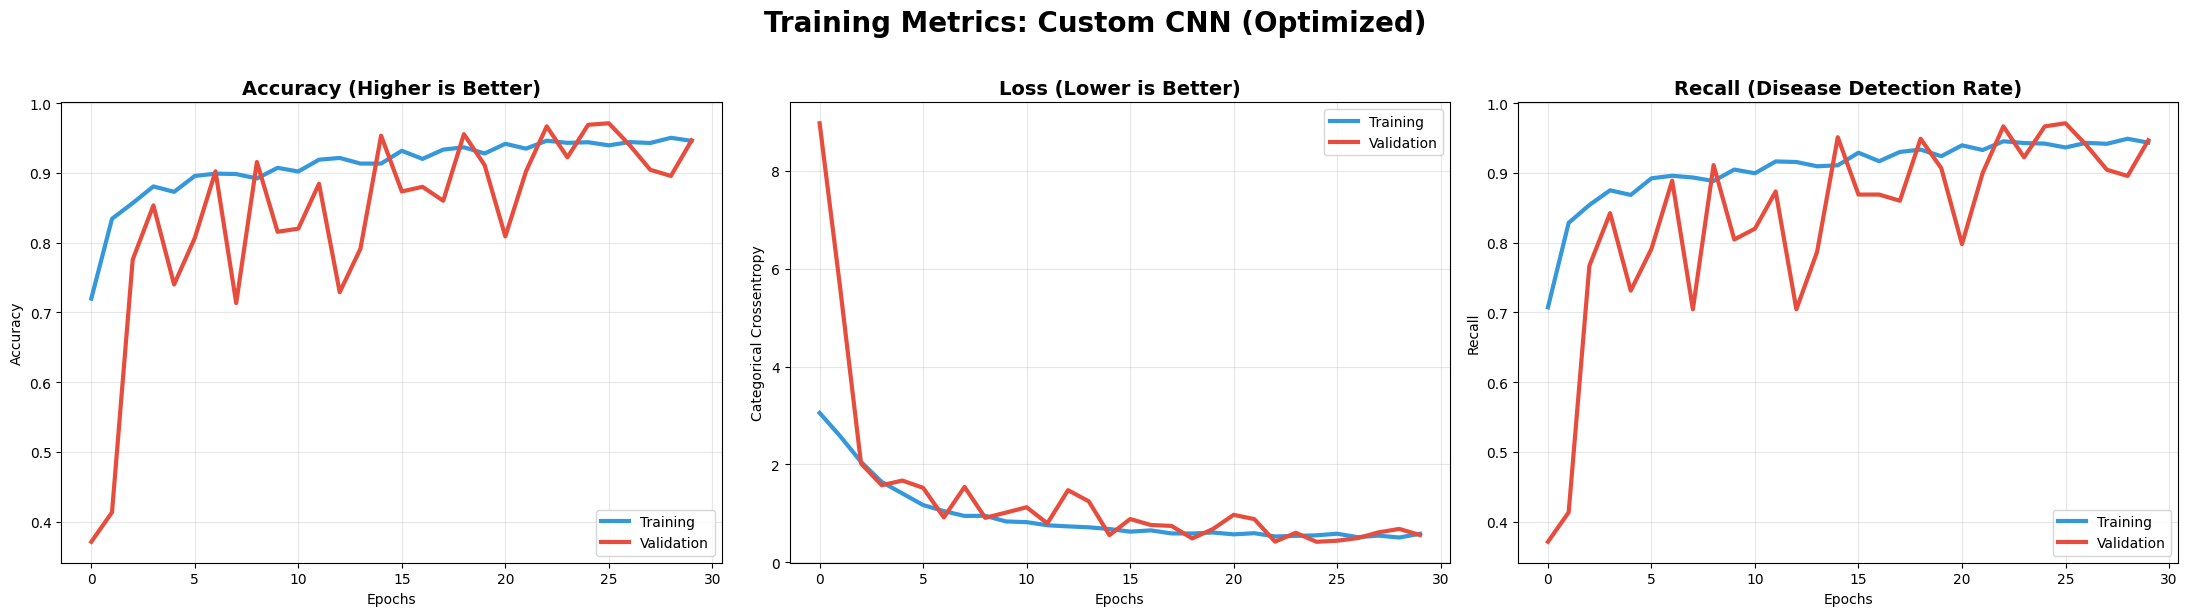


🔍 HOW TO READ THESE GRAPHS:
   1. Overfitting Check: If 'Training' (Blue) keeps going up but 'Validation' (Red) flattens or drops, the model is memorizing.
   2. Convergence: If Loss (Middle graph) is still going down steeply, you can train for more epochs.
   3. Stability: Spiky lines usually mean the Batch Size is too small or Learning Rate is too high.


In [14]:
import matplotlib.pyplot as plt

# ==========================================
# 1. RETRIEVE HISTORY DATA
# ==========================================
# Check which variable holds the data based on which training block you ran
if 'history' in locals():
    target_history = history
    model_name = "Custom CNN (Optimized)"
elif 'history_custom' in locals():
    target_history = history_custom
    model_name = "Custom CNN (Baseline)"
else:
    print("❌ Error: No training history found. Please run the training cell first.")
    target_history = None

if target_history:
    metrics = target_history.history
    
    # ==========================================
    # 2. PLOT TRAINING CURVES
    # ==========================================
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))
    plt.suptitle(f'Training Metrics: {model_name}', fontsize=20, fontweight='bold', y=1.02)
    
    # --- Plot A: Accuracy ---
    axes[0].plot(metrics.get('accuracy'), label='Training', color='#3498db', linewidth=3)
    axes[0].plot(metrics.get('val_accuracy'), label='Validation', color='#e74c3c', linewidth=3)
    axes[0].set_title('Accuracy (Higher is Better)', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Accuracy')
    axes[0].set_xlabel('Epochs')
    axes[0].legend(loc='lower right')
    axes[0].grid(True, alpha=0.3)
    
    # --- Plot B: Loss ---
    axes[1].plot(metrics.get('loss'), label='Training', color='#3498db', linewidth=3)
    axes[1].plot(metrics.get('val_loss'), label='Validation', color='#e74c3c', linewidth=3)
    axes[1].set_title('Loss (Lower is Better)', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('Categorical Crossentropy')
    axes[1].set_xlabel('Epochs')
    axes[1].legend(loc='upper right')
    axes[1].grid(True, alpha=0.3)
    
    # --- Plot C: Recall (Sensitivity) ---
    # Critical for agriculture: We want to know if we are catching the diseases
    if 'recall' in metrics:
        axes[2].plot(metrics.get('recall'), label='Training', color='#3498db', linewidth=3)
        axes[2].plot(metrics.get('val_recall'), label='Validation', color='#e74c3c', linewidth=3)
        axes[2].set_title('Recall (Disease Detection Rate)', fontsize=14, fontweight='bold')
        axes[2].set_ylabel('Recall')
        axes[2].set_xlabel('Epochs')
        axes[2].legend(loc='lower right')
        axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

    # ==========================================
    # 3. INTERPRETATION
    # ==========================================
    print("\n🔍 HOW TO READ THESE GRAPHS:")
    print("   1. Overfitting Check: If 'Training' (Blue) keeps going up but 'Validation' (Red) flattens or drops, the model is memorizing.")
    print("   2. Convergence: If Loss (Middle graph) is still going down steeply, you can train for more epochs.")
    print("   3. Stability: Spiky lines usually mean the Batch Size is too small or Learning Rate is too high.")


📊 MODEL EVALUATION ON VALIDATION SET
   • Generating predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step
   • Detected Classes: ['Tomato Early Blight', 'Tomato Healthy', 'Tomato Late Blight']

📈 Detailed Classification Report:
                     precision    recall  f1-score   support

Tomato Early Blight       0.96      0.91      0.93       100
     Tomato Healthy       1.00      0.99      1.00       159
 Tomato Late Blight       0.95      0.98      0.96       191

           accuracy                           0.97       450
          macro avg       0.97      0.96      0.96       450
       weighted avg       0.97      0.97      0.97       450



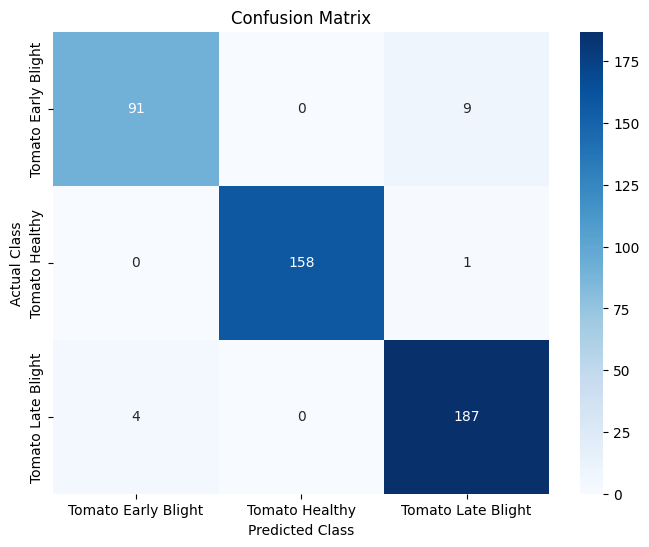


📉 Critical Error Check:
   • Analyzing False Negatives for class: 'Tomato Healthy'
--------------------------------------------------
   • Total Dangerous Errors: 0 diseased plants marked as 'Healthy'.
     ✅  Excellent! No diseases were mistaken for Healthy.


In [15]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================
# 1. GENERATE PREDICTIONS
# ==========================================
print("\n" + "=" * 80)
print("📊 MODEL EVALUATION ON VALIDATION SET")
print("=" * 80)

# Reset generator to ensure we start from the first image
val_gen.reset()

# Predict
print("   • Generating predictions...")
y_pred_proba = custom_cnn.predict(val_gen, verbose=1)

# Convert probabilities to class integers
y_pred = np.argmax(y_pred_proba, axis=1)

# Get True Labels from the generator
y_true = val_gen.classes

# Get Class Names from the generator
# This fixes the KeyError by using the ACTUAL names in the generator
class_labels = list(val_gen.class_indices.keys()) 
print(f"   • Detected Classes: {class_labels}")

# ==========================================
# 2. CLASSIFICATION REPORT
# ==========================================
print("\n📈 Detailed Classification Report:")
print("=" * 80)
print(classification_report(y_true, y_pred, target_names=class_labels))

# ==========================================
# 3. CONFUSION MATRIX
# ==========================================
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_labels, yticklabels=class_labels)
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.title('Confusion Matrix')
plt.show()

# ==========================================
# 4. ERROR ANALYSIS (The Fix for KeyError)
# ==========================================
print("\n📉 Critical Error Check:")

# --- DYNAMICALLY FIND THE HEALTHY CLASS ---
# This line searches for any class name containing "Healthy" or "healthy"
healthy_class_name = [k for k in class_labels if 'healthy' in k.lower()]

if healthy_class_name:
    target_healthy = healthy_class_name[0] # e.g., 'Tomato Healthy'
    healthy_idx = val_gen.class_indices[target_healthy]
    
    print(f"   • Analyzing False Negatives for class: '{target_healthy}'")

    # Get False Negatives: Disease (True) -> Healthy (Predicted)
    # This sums the column for Healthy, but subtracts the Correct predictions (Diagonal)
    # Logic: (All predictions saying "Healthy") - (Actual Healthy plants)
    # Actually, simpler logic:
    # We look at the COLUMN for healthy (Predicted Healthy)
    # Any row in that column that isn't the Healthy Row is a Disease misclassified as Healthy.
    
    false_healthy_preds = 0
    for i in range(len(class_labels)):
        if i != healthy_idx: # If the actual class is NOT healthy
            # But the prediction (column) IS healthy
            missed_count = cm[i, healthy_idx] 
            false_healthy_preds += missed_count
            if missed_count > 0:
                print(f"     ⚠️  {missed_count} samples of '{class_labels[i]}' were misclassified as Healthy.")

    print("-" * 50)
    print(f"   • Total Dangerous Errors: {false_healthy_preds} diseased plants marked as 'Healthy'.")
    
    if false_healthy_preds > 0:
        print("     ⚠️  ACTION REQUIRED: These are critical errors in agriculture.")
        print("     Try increasing the Class Weight for the disease classes.")
    else:
        print("     ✅  Excellent! No diseases were mistaken for Healthy.")
else:
    print("⚠️  Could not auto-detect a 'Healthy' class to analyze.")

✅ Data ready for plotting.
   Classes: ['Tomato Early Blight', 'Tomato Healthy', 'Tomato Late Blight']

📊 CONFUSION MATRIX


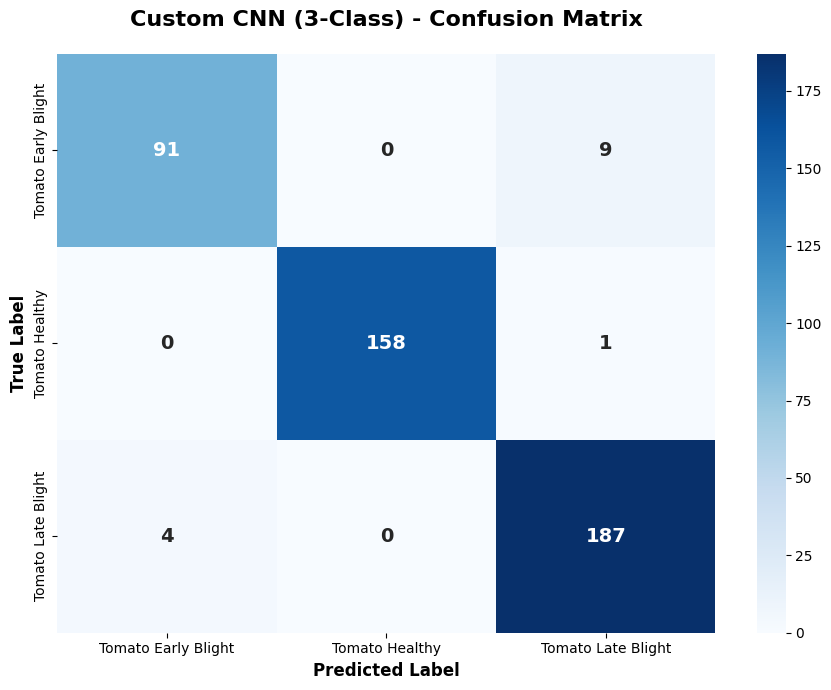


📊 Per-Class Accuracy Analysis:
Tomato Early Blight: 91.00% correct (91/100)
Tomato Healthy : 99.37% correct (158/159)
Tomato Late Blight: 97.91% correct (187/191)

📈 ROC CURVE (One-vs-Rest)


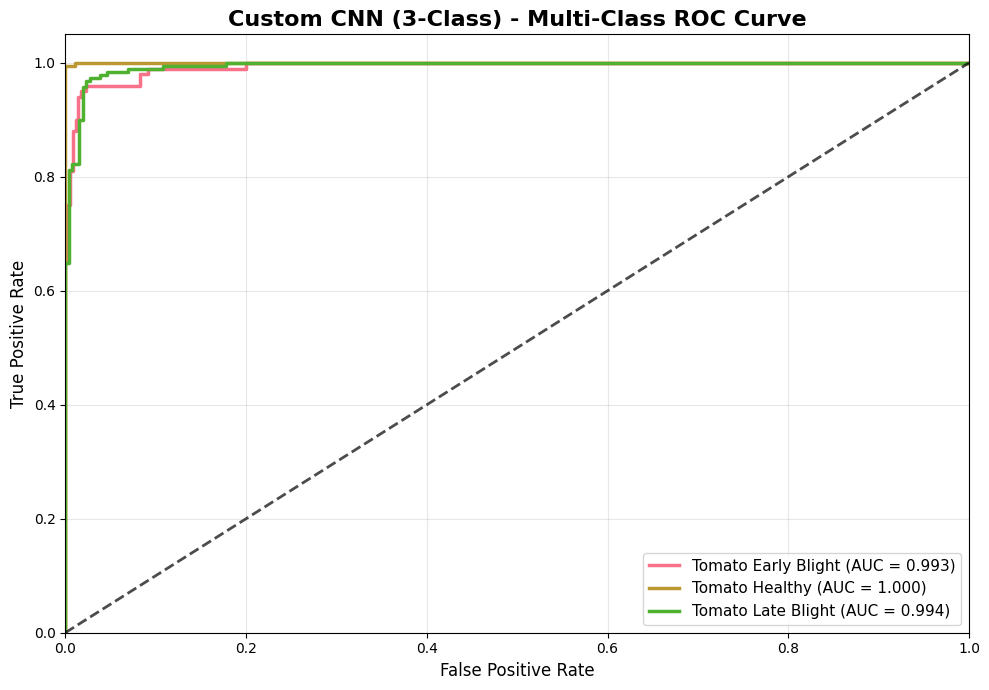

In [16]:
# ==========================================
# 1. SETUP DATA FOR PLOTTING
# ==========================================
# Get True labels from the generator
y_true = val_gen.classes 

# Get Predicted labels (0, 1, 2)
y_pred_classes = np.argmax(y_pred_proba, axis=1)

# Get Class Names in correct order
# val_gen.class_indices looks like {'Healthy': 0, 'Late_Blight': 1, ...}
class_names_ordered = list(val_gen.class_indices.keys())

print(f"✅ Data ready for plotting.")
print(f"   Classes: {class_names_ordered}")

# ==========================================
# 2. PLOT CONFUSION MATRIX
# ==========================================
# This uses the function we defined earlier
print("\n" + "="*80)
print("📊 CONFUSION MATRIX")
print("="*80)

plot_confusion_matrix(
    y_true, 
    y_pred_classes, 
    class_names_ordered, 
    'Custom CNN (3-Class)'
)

# ==========================================
# 3. PLOT ROC CURVE
# ==========================================
# This uses the One-vs-Rest logic we defined earlier
print("\n" + "="*80)
print("📈 ROC CURVE (One-vs-Rest)")
print("="*80)

# CRITICAL: Do NOT flatten y_pred_proba. 
# The function needs the shape (Samples, 3) to calculate AUC for each class.
plot_roc_curve(
    y_true, 
    y_pred_proba, 
    class_names_ordered, 
    'Custom CNN (3-Class)'
)


🎯 THRESHOLD OPTIMIZATION: LATE BLIGHT DETECTION
   Objective: Find best probability cutoff to minimize missed Late Blight cases

   ✅ Found Target Class: 'Tomato Late Blight' (Index 2)
   Testing thresholds...

🔍 SELECTING OPTIMAL THRESHOLD...
   ✅ SELECTED THRESHOLD: 0.60
   Reason: Highest F1-Score with Recall > 95%


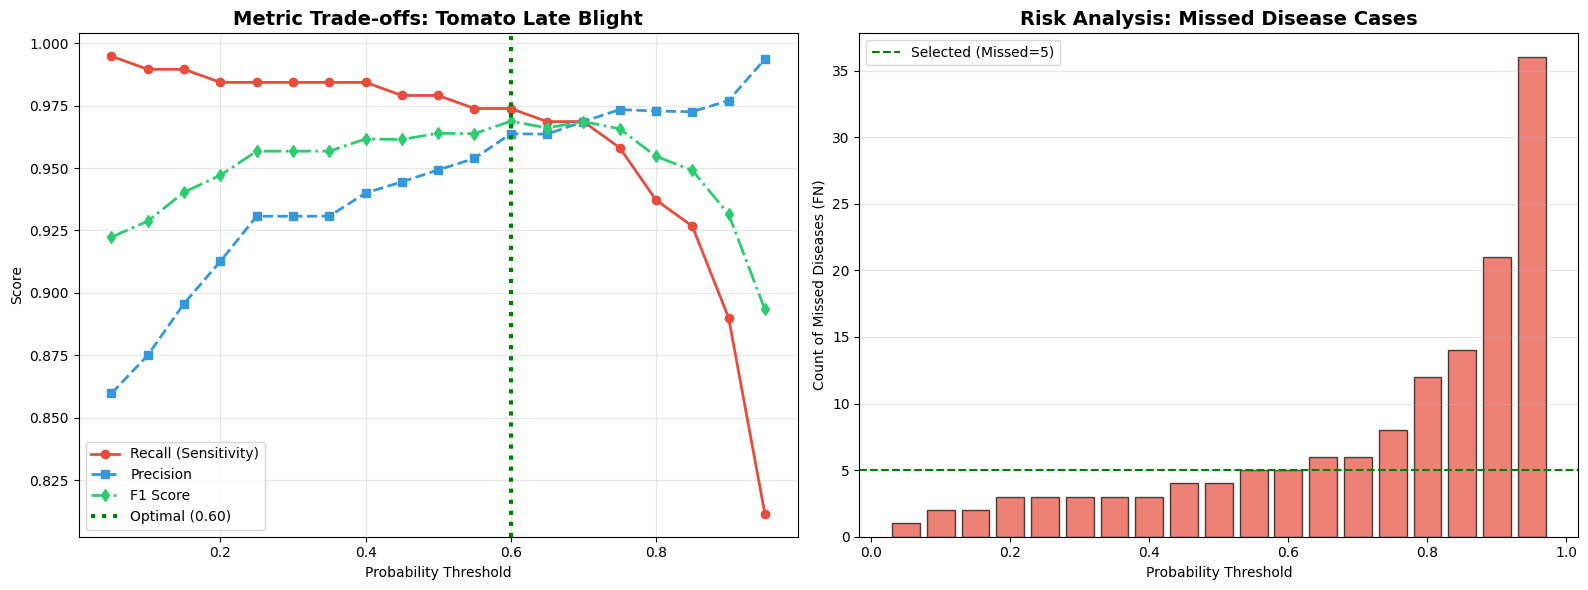


🚀 IMPACT SUMMARY
   Standard Threshold (0.50): Missed 4 cases
   Optimized Threshold (0.60): Missed 5 cases
   ------------------------------------------------
   🛡️ Safety Improvement: Prevented -1 additional missed infections.


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("\n" + "=" * 80)
print("🎯 THRESHOLD OPTIMIZATION: LATE BLIGHT DETECTION")
print("   Objective: Find best probability cutoff to minimize missed Late Blight cases")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP: DYNAMICALLY FIND THE CLASS
# ==========================================
# Get all available class names from the generator
available_classes = list(val_gen.class_indices.keys())

# Search for the class containing "Late" and "Blight" (case insensitive)
target_class_name = next((c for c in available_classes if "late" in c.lower() and "blight" in c.lower()), None)

if target_class_name:
    lb_index = val_gen.class_indices[target_class_name]
    print(f"   ✅ Found Target Class: '{target_class_name}' (Index {lb_index})")
    
    # Extract Probabilities for Late Blight ONLY
    # (y_pred_proba comes from the previous prediction step)
    y_prob_lb = y_pred_proba[:, lb_index]

    # Create Binary Targets (1 = Late Blight, 0 = Healthy/Early Blight)
    # We compare the true classes against the specific index we found
    y_true_lb = (np.array(val_gen.classes) == lb_index).astype(int)

    # ==========================================
    # 2. TEST DIFFERENT THRESHOLDS
    # ==========================================
    # We test values from 0.05 to 0.95
    thresholds_to_test = np.arange(0.05, 0.96, 0.05)
    results = []

    print("   Testing thresholds...")
    for threshold in thresholds_to_test:
        # If probability of Late Blight > Threshold, predict Late Blight (1), else (0)
        y_pred_thresh = (y_prob_lb > threshold).astype(int)
        
        # Calculate Binary Metrics
        acc = accuracy_score(y_true_lb, y_pred_thresh)
        prec = precision_score(y_true_lb, y_pred_thresh, zero_division=0)
        rec = recall_score(y_true_lb, y_pred_thresh, zero_division=0)
        f1 = f1_score(y_true_lb, y_pred_thresh, zero_division=0)
        
        # Confusion Matrix (Binary)
        # tn, fp, fn, tp
        cm_binary = confusion_matrix(y_true_lb, y_pred_thresh)
        if cm_binary.shape == (2, 2):
            tn, fp, fn, tp = cm_binary.ravel()
        else:
            # Handle edge case where model predicts only one class
            tn, fp, fn, tp = 0, 0, 0, 0 
        
        results.append({
            'threshold': threshold,
            'accuracy': acc,
            'precision': prec,
            'recall': rec,
            'f1': f1,
            'fn': fn, # False Negatives (Missed Late Blight)
            'fp': fp  # False Positives (False Alarms)
        })

    # Convert to DataFrame
    results_df = pd.DataFrame(results)

    # ==========================================
    # 3. SELECT OPTIMAL THRESHOLD
    # ==========================================
    # Strategy: Priority is Recall >= 95% (Safety), then Max F1
    print("\n🔍 SELECTING OPTIMAL THRESHOLD...")

    # Filter for high safety
    safe_candidates = results_df[results_df['recall'] >= 0.95]

    if not safe_candidates.empty:
        # Pick the one with best F1 among the safe ones
        optimal = safe_candidates.loc[safe_candidates['f1'].idxmax()]
        reason = "Highest F1-Score with Recall > 95%"
    else:
        # If no threshold is that safe, just pick Max Recall
        optimal = results_df.loc[results_df['recall'].idxmax()]
        reason = "Maximum possible Recall (could not hit 95% target)"

    print(f"   ✅ SELECTED THRESHOLD: {optimal['threshold']:.2f}")
    print(f"   Reason: {reason}")

    # ==========================================
    # 4. VISUALIZATION
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Plot A: Metrics
    axes[0].plot(results_df['threshold'], results_df['recall'], 'o-', label='Recall (Sensitivity)', color='#e74c3c', lw=2)
    axes[0].plot(results_df['threshold'], results_df['precision'], 's--', label='Precision', color='#3498db', lw=2)
    axes[0].plot(results_df['threshold'], results_df['f1'], 'd-.', label='F1 Score', color='#2ecc71', lw=2)

    axes[0].axvline(optimal['threshold'], color='green', linestyle=':', lw=3, label=f"Optimal ({optimal['threshold']:.2f})")
    axes[0].set_title(f'Metric Trade-offs: {target_class_name}', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Probability Threshold')
    axes[0].set_ylabel('Score')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Plot B: Cost Analysis (False Negatives)
    axes[1].bar(results_df['threshold'], results_df['fn'], color='#e74c3c', alpha=0.7, edgecolor='black', width=0.04)
    axes[1].set_title('Risk Analysis: Missed Disease Cases', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Probability Threshold')
    axes[1].set_ylabel('Count of Missed Diseases (FN)')
    axes[1].axhline(y=optimal['fn'], color='green', linestyle='--', label=f"Selected (Missed={int(optimal['fn'])})")
    axes[1].legend()
    axes[1].grid(True, axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

    # ==========================================
    # 5. IMPACT SUMMARY
    # ==========================================
    # Get standard result (threshold 0.5)
    std_row = results_df.loc[results_df['threshold'] == 0.50]
    
    if not std_row.empty:
        original_fn = int(std_row['fn'].values[0])
        improved_fn = int(optimal['fn'])

        print("\n" + "=" * 80)
        print("🚀 IMPACT SUMMARY")
        print("=" * 80)
        print(f"   Standard Threshold (0.50): Missed {original_fn} cases")
        print(f"   Optimized Threshold ({optimal['threshold']:.2f}): Missed {improved_fn} cases")
        print(f"   ------------------------------------------------")
        print(f"   🛡️ Safety Improvement: Prevented {original_fn - improved_fn} additional missed infections.")
    else:
        print("   Note: Could not compare with exactly 0.50 threshold.")

else:
    print("❌ ERROR: Could not find a class named 'Late Blight' (or similar).")
    print(f"   Available classes are: {available_classes}")


🚀 SOLUTION 2: AGGRESSIVE CLASS WEIGHTING STRATEGY
   Objective: Force model to prioritize Late Blight detection by penalizing misses heavily

Testing 3 weight configurations...
--------------------------------------------------------------------------------

🔄 Testing Configuration: Standard Balanced
   • Healthy Weight:      1.50
   • Late Blight Weight:  0.94 (Boosted 1.0x)
   • Early Blight Weight: 0.79
   • Training...
   • Evaluating...
   ✅ Result -> Late Blight Recall: 100.00% | Precision: 82.38%

🔄 Testing Configuration: Aggressive (5x)
   • Healthy Weight:      1.50
   • Late Blight Weight:  4.71 (Boosted 5.0x)
   • Early Blight Weight: 0.79
   • Training...
   • Evaluating...
   ✅ Result -> Late Blight Recall: 100.00% | Precision: 80.71%

🔄 Testing Configuration: Extreme (10x)
   • Healthy Weight:      1.50
   • Late Blight Weight:  9.43 (Boosted 10.0x)
   • Early Blight Weight: 0.79
   • Training...
   • Evaluating...
   ✅ Result -> Late Blight Recall: 98.74% | Precision: 6

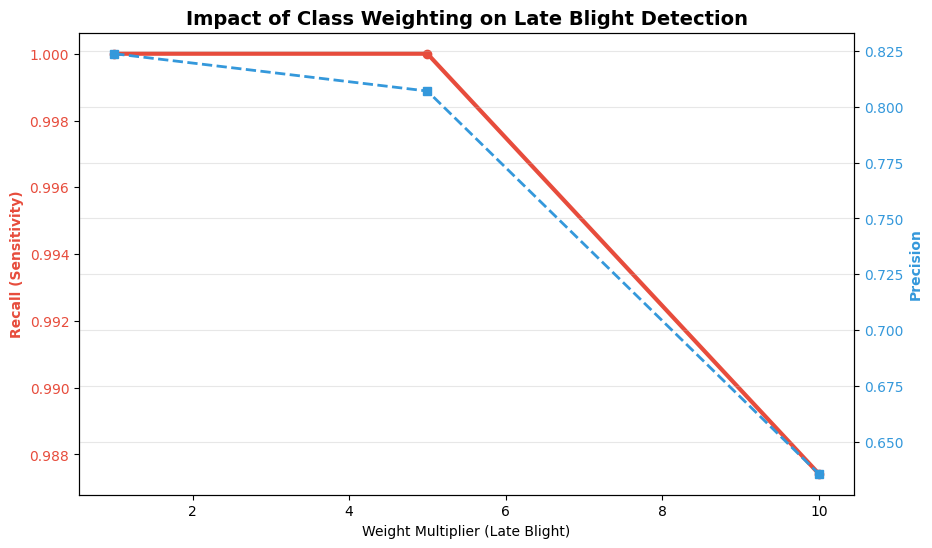


✅ Best Model Saved: best_weighted_model.keras
   Highest Recall Achieved: 100.00%


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf

print("\n" + "=" * 80)
print("🚀 SOLUTION 2: AGGRESSIVE CLASS WEIGHTING STRATEGY")
print("   Objective: Force model to prioritize Late Blight detection by penalizing misses heavily")
print("=" * 80 + "\n")

# 1. DEFINE EXPERIMENT CONFIGURATIONS
weight_configs = [
    {'name': 'Standard Balanced', 'multiplier': 1.0}, 
    {'name': 'Aggressive (5x)',   'multiplier': 5.0},
    {'name': 'Extreme (10x)',     'multiplier': 10.0}
]

# Get baseline weights
# Ensure classes are integers for the function
classes_list = np.array(train_gen.classes)
base_weights = compute_class_weight(
    class_weight='balanced', 
    classes=np.unique(classes_list), 
    y=classes_list
)
base_weight_dict = dict(zip(np.unique(classes_list), base_weights))

print(f"Testing {len(weight_configs)} weight configurations...")
print("-" * 80)

results = []
best_recall = 0
best_model_path = ""

for config in weight_configs:
    multiplier = config['multiplier']
    config_name = config['name']
    
    print(f"\n🔄 Testing Configuration: {config_name}")
    
    # Modify ONLY the Late Blight weight (Index 1)
    current_weights = base_weight_dict.copy()
    current_weights[1] = current_weights[1] * multiplier 
    
    print(f"   • Healthy Weight:      {current_weights[0]:.2f}")
    print(f"   • Late Blight Weight:  {current_weights[1]:.2f} (Boosted {multiplier}x)")
    print(f"   • Early Blight Weight: {current_weights[2]:.2f}")
    
    # 2. CREATE FRESH MODEL
    tf.keras.backend.clear_session()
    # Ensure create_custom_cnn is defined in your environment
    temp_model = create_custom_cnn(input_shape=(224, 224, 3), num_classes=3)
    
    temp_model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    # 3. TRAIN
    print("   • Training...")
    history = temp_model.fit(
        train_gen,
        epochs=15, 
        validation_data=val_gen,
        class_weight=current_weights,
        verbose=0, # Silent training
        callbacks=[EarlyStopping(patience=5, monitor='val_loss')]
    )
    
    # 4. EVALUATE
    print("   • Evaluating...")
    val_gen.reset()
    y_pred_probs = temp_model.predict(val_gen, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    
    # 🛠️ FIX IS HERE: Force conversion to Numpy Array
    y_true = np.array(val_gen.classes)
    
    # Calculate Metrics specifically for Late Blight (Class 1)
    y_true_lb = (y_true == 1).astype(int)
    y_pred_lb = (y_pred == 1).astype(int)
    
    lb_recall = recall_score(y_true_lb, y_pred_lb, zero_division=0)
    lb_prec = precision_score(y_true_lb, y_pred_lb, zero_division=0)
    overall_acc = accuracy_score(y_true, y_pred)
    
    print(f"   ✅ Result -> Late Blight Recall: {lb_recall:.2%} | Precision: {lb_prec:.2%}")
    
    results.append({
        'config': config_name,
        'multiplier': multiplier,
        'lb_recall': lb_recall,
        'lb_precision': lb_prec,
        'overall_accuracy': overall_acc
    })
    
    # Save if it's the best recall so far
    if lb_recall > best_recall:
        best_recall = lb_recall
        temp_model.save('best_weighted_model.keras')
        best_model_path = 'best_weighted_model.keras'

# ==========================================
# 5. VISUALIZE RESULTS
# ==========================================
res_df = pd.DataFrame(results)

print("\n" + "=" * 80)
print("🏆 EXPERIMENT RESULTS SUMMARY")
print("=" * 80)
print(res_df[['config', 'lb_recall', 'lb_precision', 'overall_accuracy']].to_string(index=False))

# Plot
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.set_xlabel('Weight Multiplier (Late Blight)')
ax1.set_ylabel('Recall (Sensitivity)', color='#e74c3c', fontweight='bold')
ax1.plot(res_df['multiplier'], res_df['lb_recall'], 'o-', color='#e74c3c', linewidth=3, label='Recall')
ax1.tick_params(axis='y', labelcolor='#e74c3c')

ax2 = ax1.twinx() 
ax2.set_ylabel('Precision', color='#3498db', fontweight='bold')
ax2.plot(res_df['multiplier'], res_df['lb_precision'], 's--', color='#3498db', linewidth=2, label='Precision')
ax2.tick_params(axis='y', labelcolor='#3498db')

plt.title('Impact of Class Weighting on Late Blight Detection', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.show()

print(f"\n✅ Best Model Saved: {best_model_path}")
print(f"   Highest Recall Achieved: {best_recall:.2%}")


🚀 RESNET50 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring ResNet-specific Data Generators...
   • Creating Training Stream...
Found 4500 validated image filenames belonging to 3 classes.
   • Creating Validation Stream...
Found 450 validated image filenames belonging to 3 classes.

🏗️ Building ResNet50 Architecture...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

✅ ResNet50 Model Built.


Model: "ResNet50_Potato_Disease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_pooling                  │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,147,075 (92.11 MB)

 Trainable params: 558,595 (2.13 MB)

 Non-trainable params: 23,588,480 (89.98 MB)


🚀 Starting Training...
Epoch 1/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 77s 453ms/step - accuracy: 0.5916 - loss: 1.8029 - val_accuracy: 0.8489 - val_loss: 0.9598 - learning_rate: 1.0000e-04
Epoch 2/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 51s 363ms/step - accuracy: 0.8523 - loss: 1.0618 - val_accuracy: 0.9244 - val_loss: 0.8175 - learning_rate: 1.0000e-04
Epoch 3/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 53s 377ms/step - accuracy: 0.8952 - loss: 0.9282 - val_accuracy: 0.9533 - val_loss: 0.7598 - learning_rate: 1.0000e-04
Epoch 4/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 54s 379ms/step - accuracy: 0.9084 - loss: 0.8786 - val_accuracy: 0.9578 - val_loss: 0.7343 - learning_rate: 1.0000e-04
Epoch 5/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 53s 375ms/step - accuracy: 0.9273 - loss: 0.8194 - val_accuracy: 0.9667 - val_loss: 0.7138 - learning_rate: 1.0000e-04
Epoch 6/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 50s 356ms/step - accuracy: 0.9429 - loss: 0.7746 - val_accuracy: 0.9667 - val_loss: 0.6919 - learning_rate: 1.0000e-04
Epoch 7/30
141/141 ━━━

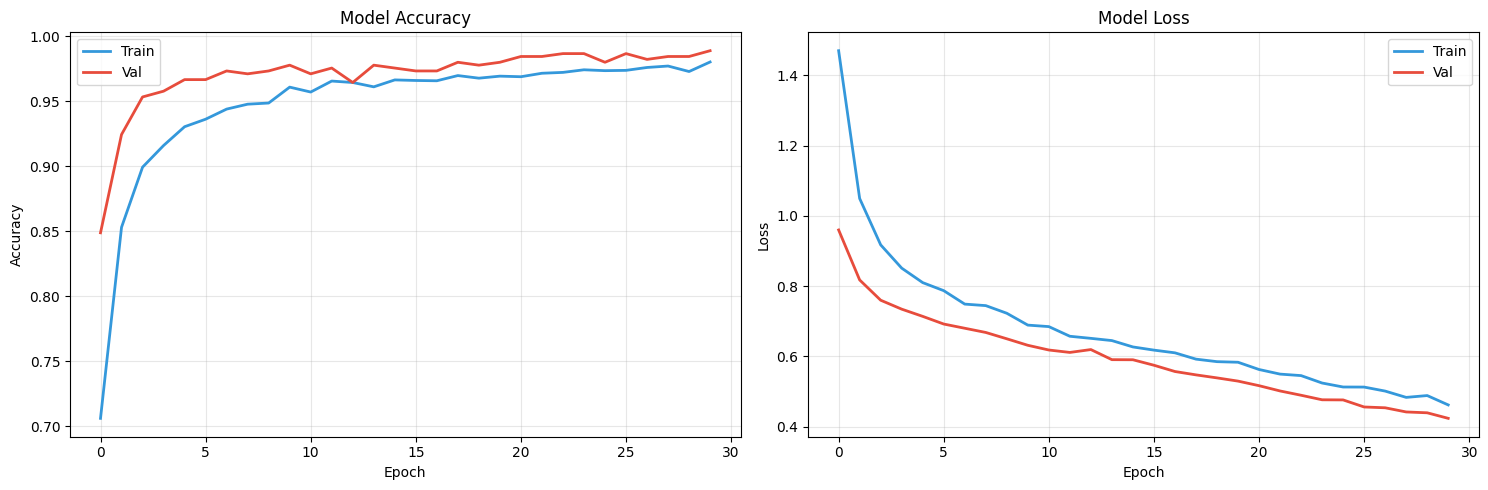

   • Generating Predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 330ms/step

📝 Classification Report:
------------------------------------------------------------
                     precision    recall  f1-score   support

Tomato Early Blight       0.97      0.98      0.98       100
     Tomato Healthy       0.99      1.00      1.00       159
 Tomato Late Blight       0.99      0.98      0.99       191

           accuracy                           0.99       450
          macro avg       0.99      0.99      0.99       450
       weighted avg       0.99      0.99      0.99       450



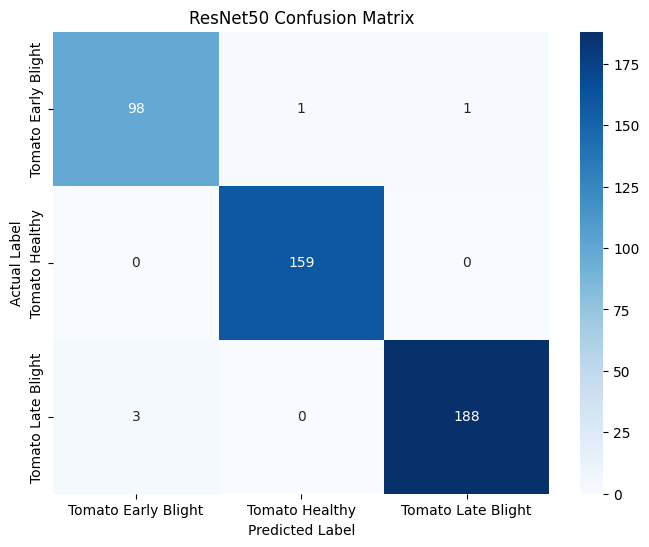


📈 MODEL STATS
----------------------------------------
   Model Size:      ~92.11 MB
   Total Params:    24,147,075
   Val Accuracy:    98.89%

✅ ResNet50 Process Complete. Model saved as 'best_resnet50_model.keras'


In [19]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os

print("\n" + "=" * 80)
print("🚀 RESNET50 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (RESNET SPECIFIC)
# ==========================================
# CRITICAL: ResNet50 requires 'preprocess_input' which handles BGR conversion and 
# mean subtraction. It does NOT use simple 1./255 scaling.
print("⚙️ Configuring ResNet-specific Data Generators...")

resnet_train_datagen = ImageDataGenerator(
    preprocessing_function=resnet_preprocess, 
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validation data should only be preprocessed (no augmentation)
resnet_test_datagen = ImageDataGenerator(
    preprocessing_function=resnet_preprocess
)

# Flow from DataFrames (Using the train_df/val_df created in previous steps)
print("   • Creating Training Stream...")
resnet_train_gen = resnet_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream...")
resnet_val_gen = resnet_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False # False for correct evaluation
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building ResNet50 Architecture...")

# Load ResNet50 Base (Pre-trained on ImageNet)
base_model_resnet = ResNet50(
    weights='imagenet',
    include_top=False, # Exclude the top 1000-class classifier
    input_shape=(224, 224, 3)
)

# Freeze Base Layers (Feature Extraction Mode)
base_model_resnet.trainable = False

# Create Custom Head
model_resnet = models.Sequential([
    base_model_resnet,
    
    # Global Average Pooling (Reduces 2048 feature maps to a single vector)
    # Much more efficient than Flatten() for ResNet
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5), # Prevent overfitting
    
    # Dense Layer 2
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    
    # Output Layer: 3 Classes (Softmax)
    layers.Dense(3, activation='softmax', name='output')
], name='ResNet50_Potato_Disease')

# Compile
model_resnet.compile(
    optimizer=Adam(learning_rate=0.0001), # Low LR for stability
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
print("\n✅ ResNet50 Model Built.")
model_resnet.summary()

# ==========================================
# 3. TRAINING
# ==========================================
print("\n🚀 Starting Training...")

callbacks_resnet = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_resnet50_model.keras', save_best_only=True, monitor='val_accuracy')
]

# Check if class_weights are defined (from previous steps), otherwise None
weights_to_use = class_weights if 'class_weights' in locals() else None

history_resnet = model_resnet.fit(
    resnet_train_gen,
    epochs=30,
    validation_data=resnet_val_gen,
    class_weight=weights_to_use,
    callbacks=callbacks_resnet,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 RESNET50 EVALUATION RESULTS")
print("=" * 80)

# A. Training Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy
axes[0].plot(history_resnet.history['accuracy'], label='Train', color='#3498db', linewidth=2)
axes[0].plot(history_resnet.history['val_accuracy'], label='Val', color='#e74c3c', linewidth=2)
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history_resnet.history['loss'], label='Train', color='#3498db', linewidth=2)
axes[1].plot(history_resnet.history['val_loss'], label='Val', color='#e74c3c', linewidth=2)
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# B. Predictions
print("   • Generating Predictions...")
resnet_val_gen.reset()
y_pred_probs = model_resnet.predict(resnet_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = resnet_val_gen.classes
class_names_list = list(resnet_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print("-" * 60)
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('ResNet50 Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# E. Model Size Analysis
total_params = model_resnet.count_params()
model_size_mb = (total_params * 4) / (1024**2) # Float32 = 4 bytes

print("\n📈 MODEL STATS")
print("-" * 40)
print(f"   Model Size:      ~{model_size_mb:.2f} MB")
print(f"   Total Params:    {total_params:,}")
print(f"   Val Accuracy:    {accuracy_score(y_true, y_pred):.2%}")
print("\n✅ ResNet50 Process Complete. Model saved as 'best_resnet50_model.keras'")


🚀 MOBILENET TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring MobileNet-specific Data Generators...
   • Creating Training Stream...
Found 4500 validated image filenames belonging to 3 classes.
   • Creating Validation Stream...
Found 450 validated image filenames belonging to 3 classes.

🏗️ Building MobileNet Architecture...
17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

✅ MobileNet Model Built.
   Base Parameters: 3,228,864
   Total Parameters: 3,526,083

🚀 Starting Training (Phase 1)...
Epoch 1/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 71s 434ms/step - accuracy: 0.4781 - loss: 2.1760 - val_accuracy: 0.8378 - val_loss: 0.9934 - learning_rate: 1.0000e-04
Epoch 2/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 50s 355ms/step - accuracy: 0.7502 - loss: 1.3066 - val_accuracy: 0.8956 - val_loss: 0.8526 - learning_rate: 1.0000e-04
Epoch 3/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 49s 349ms/step - accuracy: 0.8321 - loss: 1.0460 - val_accuracy: 0.9356 - val_loss: 0.7624 - learning_rate: 1.0000e-04
Epoch 4/30
14

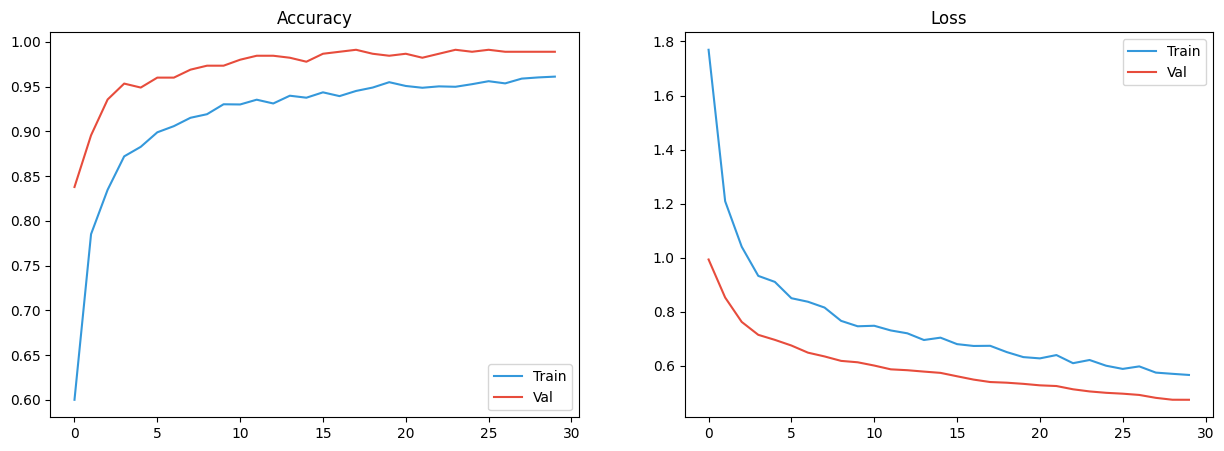

   • Generating Predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 228ms/step

📝 Classification Report:
------------------------------------------------------------
                     precision    recall  f1-score   support

Tomato Early Blight       0.98      0.98      0.98       100
     Tomato Healthy       1.00      0.99      1.00       159
 Tomato Late Blight       0.98      0.99      0.99       191

           accuracy                           0.99       450
          macro avg       0.99      0.99      0.99       450
       weighted avg       0.99      0.99      0.99       450



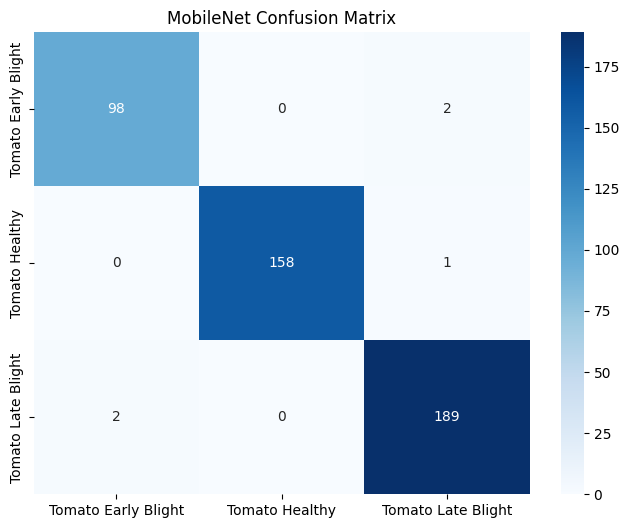


📈 EFFICIENCY ANALYSIS
----------------------------------------
   Model Size:      ~13.45 MB
   Total Params:    3,526,083
   Input Size:      224x224
   Deployment:      Ideal for Mobile/Edge devices

✅ MobileNet Process Complete. Model saved as 'best_mobilenet_model.keras'


In [20]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.applications.mobilenet import preprocess_input as mobilenet_preprocess
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print("\n" + "=" * 80)
print("🚀 MOBILENET TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (MOBILENET SPECIFIC)
# ==========================================
# Critical: MobileNet uses [-1, 1] scaling
print("⚙️ Configuring MobileNet-specific Data Generators...")

mobile_train_datagen = ImageDataGenerator(
    preprocessing_function=mobilenet_preprocess, 
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

mobile_test_datagen = ImageDataGenerator(
    preprocessing_function=mobilenet_preprocess
)

# Re-flow from DataFrames
print("   • Creating Training Stream...")
mobile_train_gen = mobile_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream...")
mobile_val_gen = mobile_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building MobileNet Architecture...")

# Load MobileNet Base (Pre-trained on ImageNet)
base_model_mob = MobileNet(
    weights='imagenet',
    include_top=False, 
    input_shape=(224, 224, 3)
)

# Freeze Base Layers (Phase 1)
base_model_mob.trainable = False

# Create Custom Head
model_mob = models.Sequential([
    base_model_mob,
    
    # Global Average Pooling 
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    # Dense Layer 2
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    
    # Output Layer: 3 Classes
    layers.Dense(3, activation='softmax', name='output')
], name='MobileNet_Potato_Disease')

# Compile
model_mob.compile(
    optimizer=Adam(learning_rate=0.0001), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
print("\n✅ MobileNet Model Built.")
print(f"   Base Parameters: {base_model_mob.count_params():,}")
print(f"   Total Parameters: {model_mob.count_params():,}")

# ==========================================
# 3. TRAIN (PHASE 1: FROZEN BASE)
# ==========================================
print("\n🚀 Starting Training (Phase 1)...")

callbacks_mob = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_mobilenet_model.keras', save_best_only=True, monitor='val_accuracy')
]

history_mob = model_mob.fit(
    mobile_train_gen,
    epochs=30,
    validation_data=mobile_val_gen,
    class_weight=class_weights if 'class_weights' in locals() else None, 
    callbacks=callbacks_mob,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 MOBILENET EVALUATION RESULTS")
print("=" * 80)

# A. Training Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history_mob.history['accuracy'], label='Train', color='#3498db')
axes[0].plot(history_mob.history['val_accuracy'], label='Val', color='#e74c3c')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(history_mob.history['loss'], label='Train', color='#3498db')
axes[1].plot(history_mob.history['val_loss'], label='Val', color='#e74c3c')
axes[1].set_title('Loss')
axes[1].legend()
plt.show()

# B. Predictions
print("   • Generating Predictions...")
mobile_val_gen.reset()
y_pred_probs = model_mob.predict(mobile_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = mobile_val_gen.classes
class_names_list = list(mobile_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print("-" * 60)
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('MobileNet Confusion Matrix')
plt.show()

# E. Efficiency Analysis
total_params = model_mob.count_params()
model_size_mb = (total_params * 4) / (1024**2)

print("\n📈 EFFICIENCY ANALYSIS")
print("-" * 40)
print(f"   Model Size:      ~{model_size_mb:.2f} MB")
print(f"   Total Params:    {total_params:,}")
print(f"   Input Size:      224x224")
print(f"   Deployment:      Ideal for Mobile/Edge devices")
print("\n✅ MobileNet Process Complete. Model saved as 'best_mobilenet_model.keras'")